<div align="center">

# Trabajo Práctico: Predicción de Precios de Casas

**Aprendizaje Automático 1 — Tecnicatura en Inteligencia Artificial (FCEIA)**

</div>

---

**Integrantes:** 
* Aiup, Agustín.
* Paoloni, Franco.
* Silva, Julián.

---

## Librerias y Dataset

In [1]:
# Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.linear_model import Lasso, Ridge
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from IPython.display import display


# Parámetros para las tablas.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Tema para los gráficos.
sns.set_theme(style="whitegrid")

# Semilla global.
RANDOM_STATE = 42

In [2]:
house_pricing = pd.read_csv(("../data/house-prices-tp.csv"))

## Análisis Exploratorio

En esta sección se elabora un primer diagnóstico del conjunto de datos.

### Estructura General

In [3]:
print(f"Dimensiones del Dataset: {house_pricing.shape[0]} filas x {house_pricing.shape[1]} columnas.")

Dimensiones del Dataset: 556 filas x 14 columnas.


In [4]:
house_pricing.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.072,0.000,4.490,0.000,0.449,6.121,56.800,3.748,3.000,247.000,18.500,395.150,8.440,22.200
1,0.083,0.000,13.920,0.000,0.437,6.127,18.400,5.503,4.000,289.000,16.000,396.900,8.580,23.900
2,0.128,12.500,6.070,0.000,0.409,5.885,33.000,6.498,4.000,345.000,18.900,396.900,8.790,20.900
3,0.089,21.000,5.640,0.000,0.439,5.963,45.700,6.815,4.000,243.000,16.800,395.560,13.450,19.700
4,0.114,0.000,8.560,0.000,0.520,6.781,71.300,2.856,5.000,384.000,20.900,395.580,7.670,26.500
5,0.063,0.000,11.930,0.000,0.573,6.593,69.100,2.479,1.000,273.000,21.000,391.990,9.670,22.400
6,0.358,0.000,6.200,1.000,0.507,6.951,88.500,2.862,8.000,307.000,17.400,391.700,9.710,26.700
7,0.088,0.000,10.810,0.000,0.413,6.417,6.600,5.287,4.000,305.000,19.200,383.730,6.720,24.200
8,1.355,0.000,8.140,0.000,0.538,6.072,100.000,4.175,4.000,307.000,21.000,376.730,13.040,14.500
9,0.303,0.000,7.380,0.000,0.493,6.312,28.900,5.416,5.000,287.000,19.600,396.900,6.150,23.000


In [5]:
house_pricing.tail(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
546,0.664,20.000,3.970,0.000,0.647,7.333,100.000,1.895,5.000,264.000,13.000,383.290,7.790,36.000
547,0.028,75.000,2.950,0.000,0.428,6.595,21.800,5.401,3.000,252.000,18.300,395.630,4.320,30.800
548,0.575,0.000,6.200,0.000,0.507,8.337,73.300,3.838,8.000,307.000,17.400,385.910,2.470,41.700
549,0.323,0.000,21.890,0.000,0.624,5.942,93.500,1.967,4.000,437.000,21.200,378.250,16.900,17.400
550,0.087,45.000,3.440,0.000,0.437,7.178,26.300,6.480,5.000,398.000,15.200,390.490,2.870,36.400
551,0.082,30.000,4.930,0.000,0.428,6.481,18.500,6.190,6.000,300.000,16.600,379.410,6.360,23.700
552,0.475,0.000,9.900,0.000,0.544,6.113,58.800,4.002,4.000,304.000,18.400,396.230,12.730,21.000
553,0.250,0.000,21.890,0.000,0.624,5.857,98.200,1.669,4.000,437.000,21.200,392.040,21.320,13.300
554,32.504,6.529,8.937,1.000,NaN,4.017,NaN,5.244,20.417,197.237,19.639,6.267,7.034,23.029
555,0.239,0.000,9.690,0.000,0.585,6.019,65.300,2.409,6.000,391.000,19.200,396.900,12.920,21.200


In [6]:
house_pricing.info()

<class 'pandas.DataFrame'>
RangeIndex: 556 entries, 0 to 555
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     533 non-null    float64
 1   ZN       534 non-null    float64
 2   INDUS    541 non-null    float64
 3   CHAS     533 non-null    float64
 4   NOX      532 non-null    float64
 5   RM       535 non-null    float64
 6   AGE      532 non-null    float64
 7   DIS      541 non-null    float64
 8   RAD      528 non-null    float64
 9   TAX      538 non-null    float64
 10  PTRATIO  528 non-null    float64
 11  B        534 non-null    float64
 12  LSTAT    534 non-null    float64
 13  MEDV     535 non-null    float64
dtypes: float64(14)
memory usage: 60.9 KB


Del análisis anterior se desprende la presencia de una gran cantidad de datos faltantes (causa del porque `pandas` no reconoce de manera efectiva los tipos de variables). Antes de seguir elaborando descripciones de los datos, se proecde a investigar estos datos nulos.

### Análisis de Valores Faltantes

Primero se eliminan las observación en donde `MEDV` tiene datos faltantes. Se procede de esta forma en lugar de imputar los datos, para no entrenar un modelo y estimar una variable con etiquetas no observadas.

In [7]:
print(f"La variable de respuesta 'MEDV' tiene {house_pricing['MEDV'].isna().sum()} datos faltantes.")

# Procedemos a eliminar los datos faltantes
house_pricing = house_pricing.dropna(subset = ['MEDV'])
print(f"\n El DataFrame ahora tiene {len(house_pricing)} observaciones.")

La variable de respuesta 'MEDV' tiene 21 datos faltantes.

 El DataFrame ahora tiene 535 observaciones.


Con el nuevo dataset, se analizan los datos que restan:

* Total de valores faltantes.
* Total de valores faltantes por variable (columnas).
* Total de valores faltantes por observacion (fila).


 Total de valores faltantes : 115

 Total de valores faltantes (por variable): 
   variable  nulos_x_variable  proporcion
0       RAD                12       2.243
1      CRIM                11       2.056
2       AGE                11       2.056
3        ZN                11       2.056
4      CHAS                 9       1.682
5       NOX                 9       1.682
6     LSTAT                 9       1.682
7         B                 9       1.682
8       TAX                 9       1.682
9   PTRATIO                 9       1.682
10       RM                 7       1.308
11      DIS                 5       0.935
12    INDUS                 4       0.748
13     MEDV                 0       0.000

 Total de filas con datos faltantes: 29

 Filas con datos faltantes: 
     nro_fila  nulos_x_obs  proporcion
0         88            9      69.231
1        248            8      61.538
2        504            8      61.538
3        223            7      53.846
4        234            7  

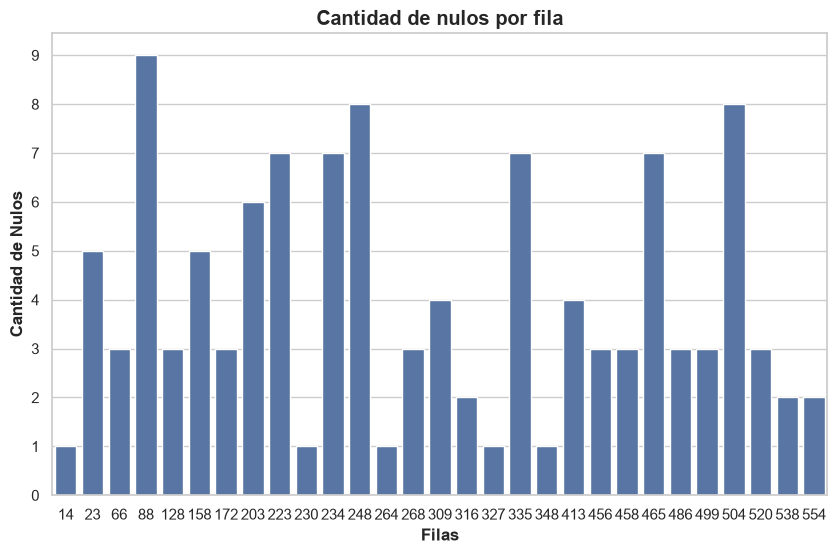

In [8]:
# Total de valores faltantes
total_nulos = (house_pricing.isna().sum().sum())

# Total de valores faltantes por variable (columnas):
total_nulos_variable = pd.DataFrame({
    'nulos_x_variable' : house_pricing.isna().sum(),
    'proporcion' : ((house_pricing.isna().sum() / len(house_pricing)) * 100)
    }).sort_values(by = 'proporcion', ascending = False)

total_nulos_variable = total_nulos_variable.reset_index()
total_nulos_variable = total_nulos_variable.rename(columns = {'index' : 'variable'})

# Total de valores faltantes por observación (filas):
total_nulos_filas = pd.DataFrame({
    'nulos_x_obs' : house_pricing.isna().sum(axis = 1),
    'proporcion' :  ((house_pricing.isna().sum(axis = 1) / 13)*100)
}).sort_values(by = 'proporcion', ascending = False)

total_nulos_filas = total_nulos_filas[total_nulos_filas['proporcion'] > 0]
total_nulos_filas = total_nulos_filas.reset_index()
total_nulos_filas = total_nulos_filas.rename(columns = {'index' : 'nro_fila'})


print(f"\n Total de valores faltantes : {total_nulos}")
print(f"\n Total de valores faltantes (por variable): \n{total_nulos_variable}")
print(f"\n Total de filas con datos faltantes: {len(total_nulos_filas)}")
print(f"\n Filas con datos faltantes: \n {total_nulos_filas}")
print(f"\n Promedio de faltantes por fila: {round(total_nulos_filas['nulos_x_obs'].mean(), 0)}")


# Graficamos la cantidad de las filas con faltantes

y_ticks = np.arange(0, 10, 1)

fig, ax = plt.subplots(figsize = (10, 6))
sns.barplot(total_nulos_filas, x = 'nro_fila', y = 'nulos_x_obs')
ax.set_title('Cantidad de nulos por fila', fontweight = 'bold', size = 'large')
ax.set_xlabel('Filas', fontweight = 'bold')
ax.set_ylabel('Cantidad de Nulos', fontweight = 'bold')
ax.set_yticks(y_ticks)
plt.show()

Se observa que 29 filas de 535 presentan valores faltantes (aprox. 5% de las observaciones restantes). A su vez, en promedio, faltan 4 de las 13 variables predictoras por fila, es decir casi un tercio de cada observación afectada.

Imputar consiste en estimar el valor faltante a partir del resto de la información de esa misma fila y del conjunto. Con ese nivel de deterioro queda poca información sobre la cual apoyar la estimación: esas filas entrarían al modelo con más valores construidos por nosotros que medidos, y pesarían igual que las reales durante el ajuste. Como además representan apenas el 5% de los datos, el costo de eliminarlas es bajo frente al riesgo de sesgar el modelo imputándolas.

In [9]:
house_pricing = house_pricing.dropna().reset_index(drop = True)

print(f"El DataFrame ahora quedó con {house_pricing.shape[0]} observaciones y {house_pricing.shape[1]} variables.")

El DataFrame ahora quedó con 506 observaciones y 14 variables.


### Estadísticas Descriptivas (post Tratmiento de Datos Faltantes)

In [10]:
house_pricing.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.072,0.000,4.490,0.000,0.449,6.121,56.800,3.748,3.000,247.000,18.500,395.150,8.440,22.200
1,0.083,0.000,13.920,0.000,0.437,6.127,18.400,5.503,4.000,289.000,16.000,396.900,8.580,23.900
2,0.128,12.500,6.070,0.000,0.409,5.885,33.000,6.498,4.000,345.000,18.900,396.900,8.790,20.900
3,0.089,21.000,5.640,0.000,0.439,5.963,45.700,6.815,4.000,243.000,16.800,395.560,13.450,19.700
4,0.114,0.000,8.560,0.000,0.520,6.781,71.300,2.856,5.000,384.000,20.900,395.580,7.670,26.500
5,0.063,0.000,11.930,0.000,0.573,6.593,69.100,2.479,1.000,273.000,21.000,391.990,9.670,22.400
6,0.358,0.000,6.200,1.000,0.507,6.951,88.500,2.862,8.000,307.000,17.400,391.700,9.710,26.700
7,0.088,0.000,10.810,0.000,0.413,6.417,6.600,5.287,4.000,305.000,19.200,383.730,6.720,24.200
8,1.355,0.000,8.140,0.000,0.538,6.072,100.000,4.175,4.000,307.000,21.000,376.730,13.040,14.500
9,0.303,0.000,7.380,0.000,0.493,6.312,28.900,5.416,5.000,287.000,19.600,396.900,6.150,23.000


In [11]:
house_pricing.tail(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
496,0.051,0.000,5.190,0.000,0.515,6.316,38.100,6.458,5.000,224.000,20.200,389.710,5.680,22.200
497,0.664,20.000,3.970,0.000,0.647,7.333,100.000,1.895,5.000,264.000,13.000,383.290,7.790,36.000
498,0.028,75.000,2.950,0.000,0.428,6.595,21.800,5.401,3.000,252.000,18.300,395.630,4.320,30.800
499,0.575,0.000,6.200,0.000,0.507,8.337,73.300,3.838,8.000,307.000,17.400,385.910,2.470,41.700
500,0.323,0.000,21.890,0.000,0.624,5.942,93.500,1.967,4.000,437.000,21.200,378.250,16.900,17.400
501,0.087,45.000,3.440,0.000,0.437,7.178,26.300,6.480,5.000,398.000,15.200,390.490,2.870,36.400
502,0.082,30.000,4.930,0.000,0.428,6.481,18.500,6.190,6.000,300.000,16.600,379.410,6.360,23.700
503,0.475,0.000,9.900,0.000,0.544,6.113,58.800,4.002,4.000,304.000,18.400,396.230,12.730,21.000
504,0.250,0.000,21.890,0.000,0.624,5.857,98.200,1.669,4.000,437.000,21.200,392.040,21.320,13.300
505,0.239,0.000,9.690,0.000,0.585,6.019,65.300,2.409,6.000,391.000,19.200,396.900,12.920,21.200


Teniendo en cuenta la naturaleza de las variables `CHAS`, `RAD` y `TAX`, se procede a modificar el tipo de dato.

In [12]:
house_pricing['CHAS'] = house_pricing['CHAS'].astype('category')
house_pricing['RAD'] = house_pricing['RAD'].astype('int64')
house_pricing['TAX'] = house_pricing['TAX'].astype('int64')

house_pricing.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float64 
 1   ZN       506 non-null    float64 
 2   INDUS    506 non-null    float64 
 3   CHAS     506 non-null    category
 4   NOX      506 non-null    float64 
 5   RM       506 non-null    float64 
 6   AGE      506 non-null    float64 
 7   DIS      506 non-null    float64 
 8   RAD      506 non-null    int64   
 9   TAX      506 non-null    int64   
 10  PTRATIO  506 non-null    float64 
 11  B        506 non-null    float64 
 12  LSTAT    506 non-null    float64 
 13  MEDV     506 non-null    float64 
dtypes: category(1), float64(11), int64(2)
memory usage: 52.0 KB


Se analizan las principales medidas y se grafican las distribuciones.

In [13]:
house_pricing.describe()

,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000,506.000
mean,3.614,11.364,11.137,0.555,6.285,68.575,3.795,9.549,408.237,18.456,356.674,12.653,22.533
std,8.602,23.322,6.860,0.116,0.703,28.149,2.106,8.707,168.537,2.165,91.295,7.141,9.197
min,0.006,0.000,0.460,0.385,3.561,2.900,1.130,1.000,187.000,12.600,0.320,1.730,5.000
25%,0.082,0.000,5.190,0.449,5.885,45.025,2.100,4.000,279.000,17.400,375.377,6.950,17.025
50%,0.257,0.000,9.690,0.538,6.208,77.500,3.207,5.000,330.000,19.050,391.440,11.360,21.200
75%,3.677,12.500,18.100,0.624,6.623,94.075,5.188,24.000,666.000,20.200,396.225,16.955,25.000
max,88.976,100.000,27.740,0.871,8.780,100.000,12.127,24.000,711.000,22.000,396.900,37.970,50.000


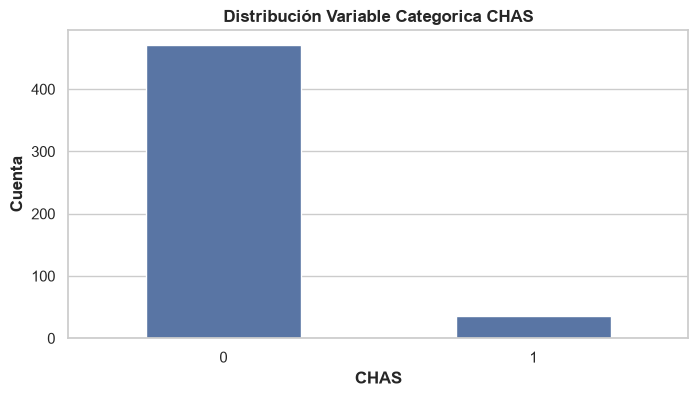

In [14]:
fig, ax = plt.subplots(figsize = (8, 4))

sns.countplot(house_pricing, x = 'CHAS', width = 0.5)
ax.set_title('Distribución Variable Categorica CHAS', fontweight = 'bold')
ax.set_xlabel('CHAS', fontweight = 'bold')
ax.set_xticks([0, 1])
ax.set_xticklabels(['0', '1'])
ax.set_ylabel('Cuenta', fontweight = 'bold')
plt.show()

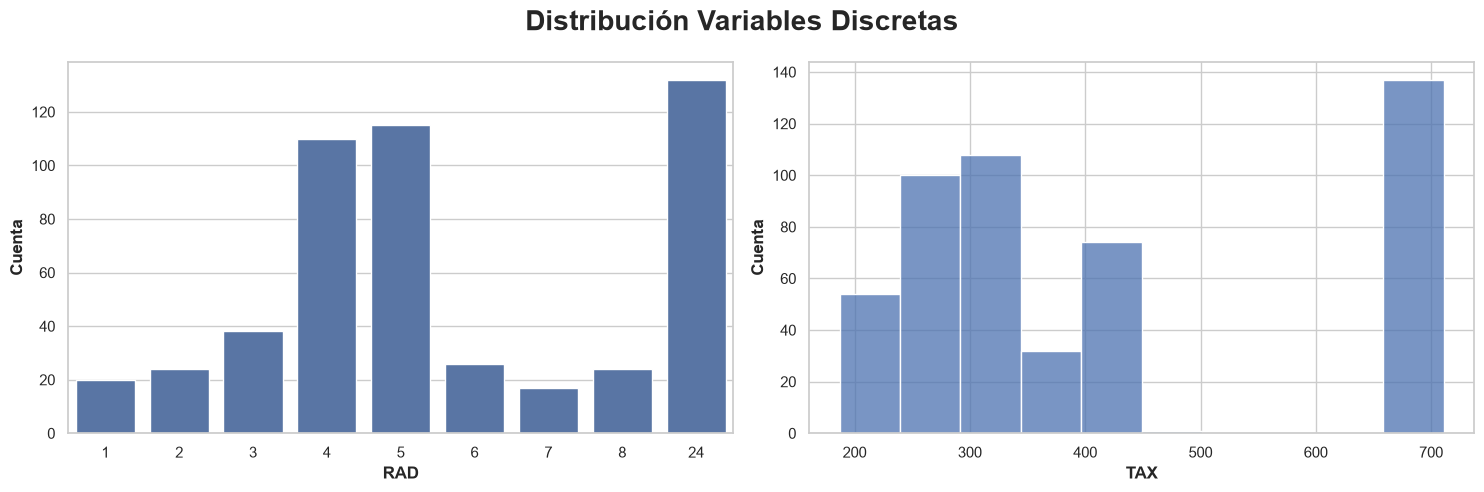

In [15]:
columnas_discretas = ['RAD', 'TAX']

fig, axes = plt.subplots(ncols = 2, nrows = 1, figsize = (15, 5))
axes = axes.flatten()

for columna, ax in zip(columnas_discretas, axes):
    if columna == 'TAX':
        sns.histplot(house_pricing, x = columna, ax = ax)
        ax.set_xlabel(columna, fontweight = 'bold')
    else:
        sns.countplot(house_pricing, x = columna, ax = ax)
        ax.set_xlabel(columna, fontweight = 'bold')

    ax.set_ylabel("Cuenta", fontweight = 'bold', fontsize = 12)


plt.suptitle('Distribución Variables Discretas', fontweight = 'bold', fontsize = 20)
plt.tight_layout()
plt.show()

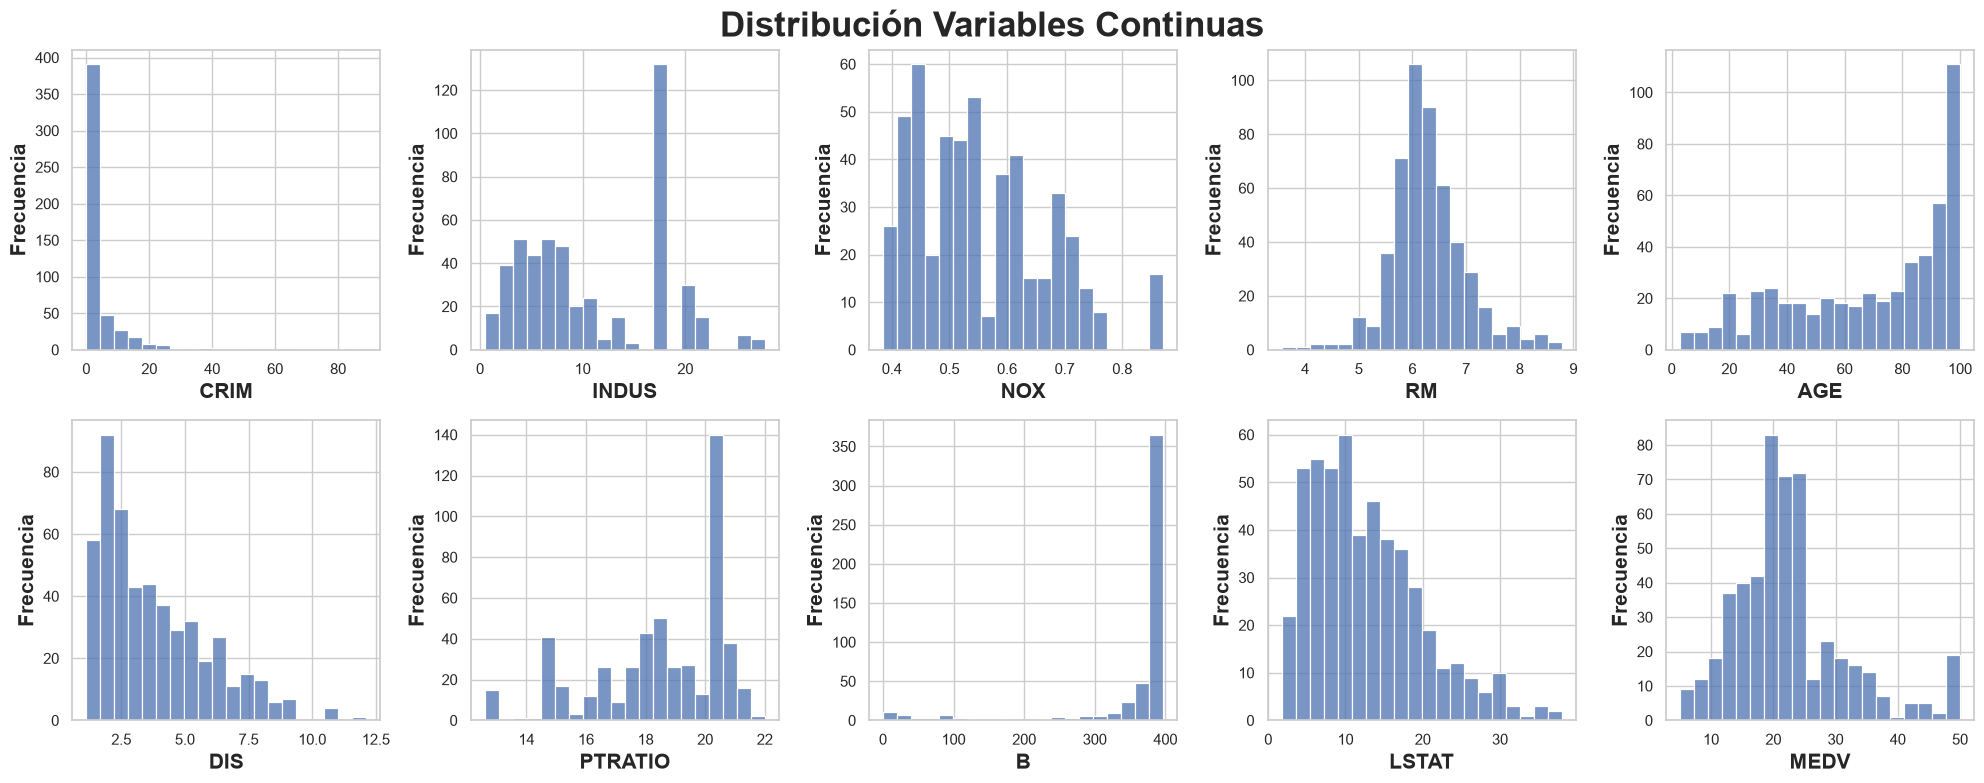

In [16]:
columnas_histograma = []

for columna in house_pricing.columns:
    if columna not in ['ZN', 'CHAS', 'RAD', 'TAX']:
        columnas_histograma.append(columna)


fig, axes = plt.subplots(ncols = 5, nrows = 4, figsize = (20, 15))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_histograma):
    sns.histplot(house_pricing, x = columna, ax = ax, bins = 20)
    ax.set_ylabel('Frecuencia', fontweight = 'bold', fontsize = 15)
    ax.set_xlabel(columna, fontweight = 'bold', fontsize = 15)


for i in range(len(columnas_histograma), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Distribución Variables Continuas', fontweight = 'bold', fontsize = 25)
plt.tight_layout()
plt.show()


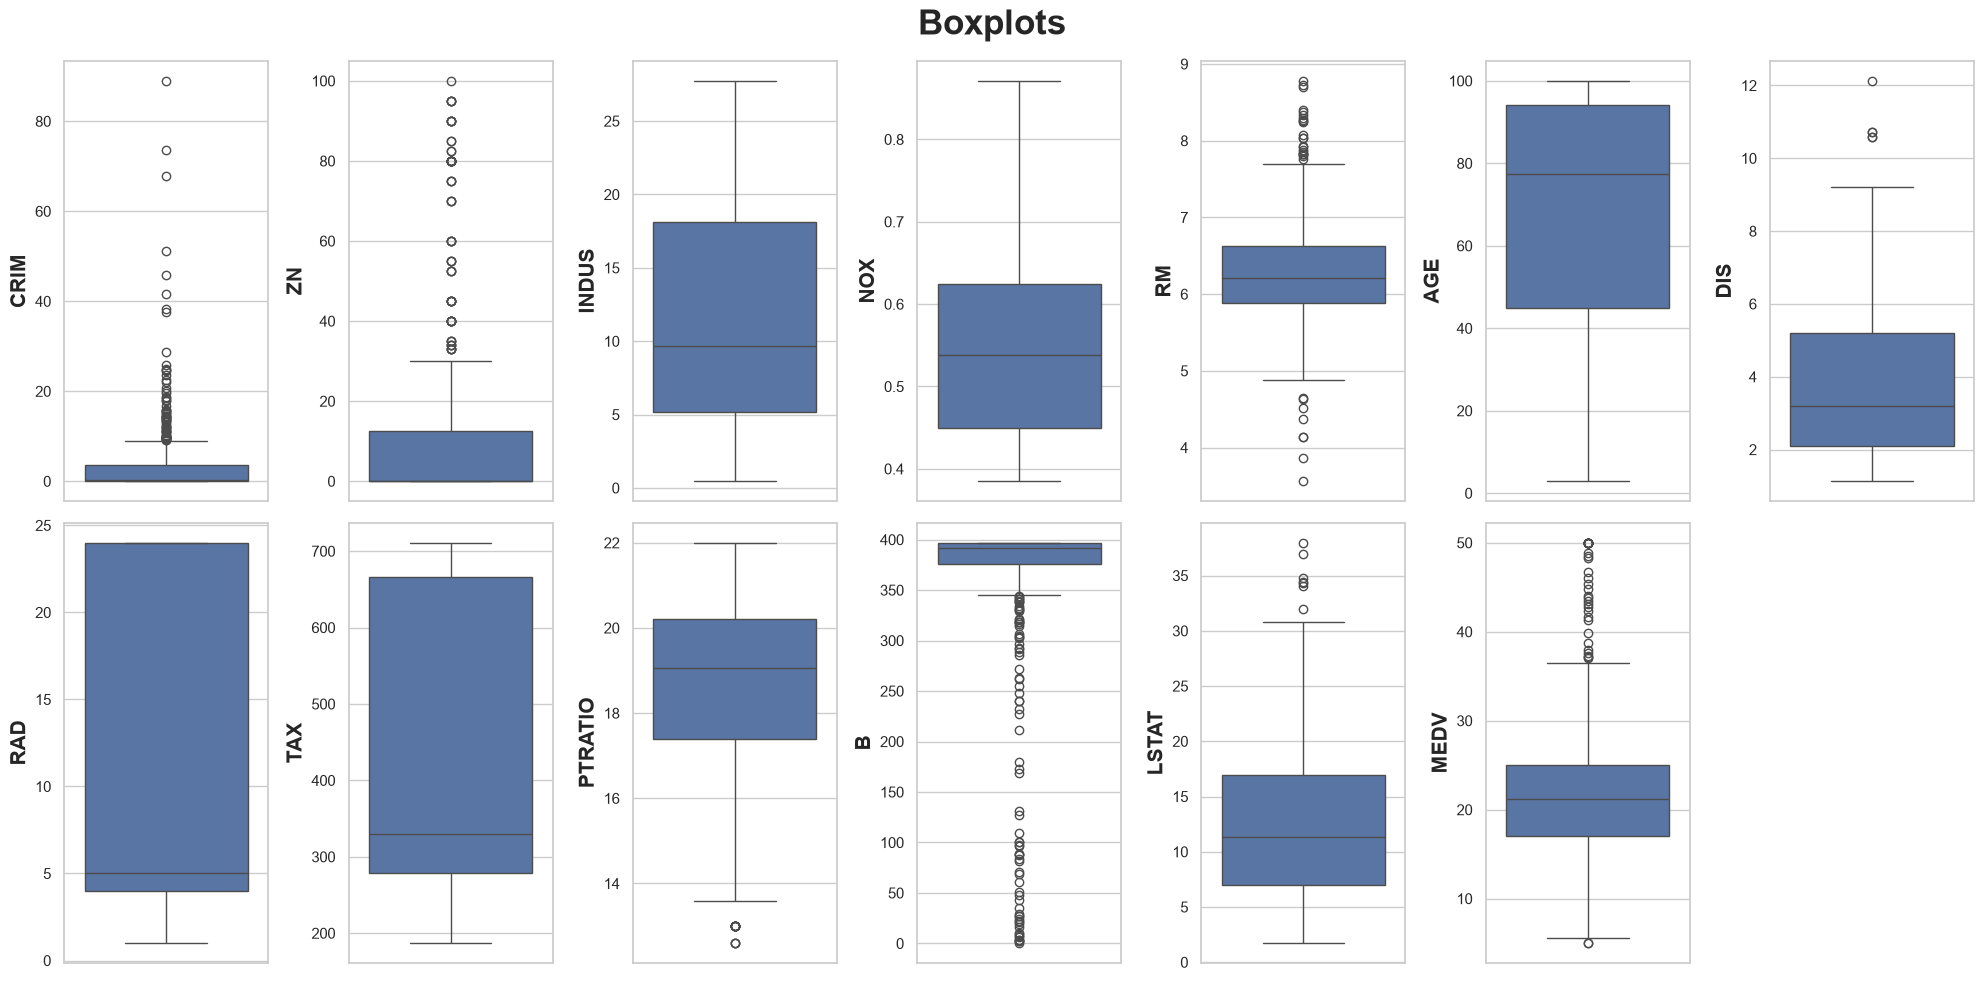

In [17]:
columnas_boxplot = []

for columna in house_pricing.columns:
    if columna != 'CHAS':
        columnas_boxplot.append(columna)

fig, axes = plt.subplots(ncols=7, nrows=2, figsize=(20, 10))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_boxplot):
    sns.boxplot(data=house_pricing, y=columna, ax=ax)
    ax.set_ylabel(columna, fontweight = 'bold', fontsize = 15)


fig.delaxes(axes[13])
fig.suptitle('Boxplots', fontweight = 'bold', fontsize = 25)
plt.tight_layout()
plt.show()

### Análisis de Outliers

Los boxplots de la sección anterior muestran valores alejados del cuerpo de cada distribución. Para determinar qué datos serían considerados _outliers_, se aplica el criterio del rango intercuartílico (IQR). Se consideran atípicos los valores que caen a más de 1,5 IQR por debajo del primer cuartil o por encima del tercero.

In [18]:
columnas_iqr = []
for columna in house_pricing.columns:
    if columna != 'CHAS':
        columnas_iqr.append(columna)

conteo_outliers = []

for columna in columnas_iqr:
    q1 = house_pricing[columna].quantile(0.25)
    q3 = house_pricing[columna].quantile(0.75)
    iqr = q3 - q1

    fuera_de_rango = (house_pricing[columna] < q1 - 1.5 * iqr) | (house_pricing[columna] > q3 + 1.5 * iqr)

    conteo_outliers.append({
        'variable' : columna,
        'outliers' : fuera_de_rango.sum(),
        'proporcion' : (fuera_de_rango.sum() / len(house_pricing)) * 100,
        'asimetria' : house_pricing[columna].skew()
    })

# Se ordena de mayor a menor cantidad de atípicos y se agrega la asimetría para interpretarlos.
outliers_iqr = pd.DataFrame(conteo_outliers).sort_values(by = 'outliers', ascending = False).reset_index(drop = True)

print(f"\n Outliers por variable (criterio IQR): \n{outliers_iqr}")


 Outliers por variable (criterio IQR): 
   variable  outliers  proporcion  asimetria
0         B        77      15.217     -2.890
1        ZN        68      13.439      2.226
2      CRIM        66      13.043      5.223
3      MEDV        40       7.905      1.108
4        RM        30       5.929      0.404
5   PTRATIO        15       2.964     -0.802
6     LSTAT         7       1.383      0.906
7       DIS         5       0.988      1.012
8     INDUS         0       0.000      0.295
9       NOX         0       0.000      0.729
10      TAX         0       0.000      0.670
11      AGE         0       0.000     -0.599
12      RAD         0       0.000      1.005


A pesar de que algunas variables muestran gran cantidad de _outliers_, conviene analizarlos antes de decidir qué hacer con ellos.

El criterio marca valores en 8 de las 13 variables. Ordenadas de mayor a menor cantidad: `B` (77), `ZN` (68), `CRIM` (66), `MEDV` (40), `RM` (30), `PTRATIO` (15), `LSTAT` (7) y `DIS` (5). Las cinco restantes no registran ninguno. Esa distribución tan despareja ya sugiere que no todos responden al mismo fenómeno.

**Colas genuinas.** `CRIM` presenta una asimetría de 5,22, la más alta del conjunto. Se trata de una cola larga y no de errores de medición: hay pocos barrios con criminalidad muy elevada, y son justamente los que explican los precios más bajos. Eliminarlos sería descartar la parte del rango que el modelo necesita aprender.

**Artefactos del criterio.** El rango intercuartílico supone distribuciones aproximadamente simétricas, y `ZN` y `B` no lo son: ambas tienen asimetría marcada y sus cuartiles quedan muy juntos, de modo que el límite de 1,5 IQR cae dentro del rango de valores legítimos. Lo que el criterio señala en estas dos variables es su forma, no observaciones anómalas.

**El techo de `MEDV`.** La variable de respuesta tiene un máximo de 50,0 y varias de sus observaciones atípicas se ubican exactamente en ese valor. El precio está censurado en ese tope, lo que limita el desempeño alcanzable en el extremo superior y se retomará al analizar los residuos.

Eliminar todo lo marcado implicaría descartar los barrios de mayor criminalidad, los de zonificación amplia y las viviendas más caras, es decir buena parte de la variabilidad que el modelo necesita para aprender. Por lo tanto, los valores atípicos **se documentan y se tienen en cuenta en la interpretación, pero no se eliminan**.

### Matriz de Correlación

Se realiza un análisis de correlación para identificar qué predictoras se asocian con `MEDV` y detectar asociaciones fuertes entre predictoras.

Primero se realiza una matriz de correlacion de Pearson.

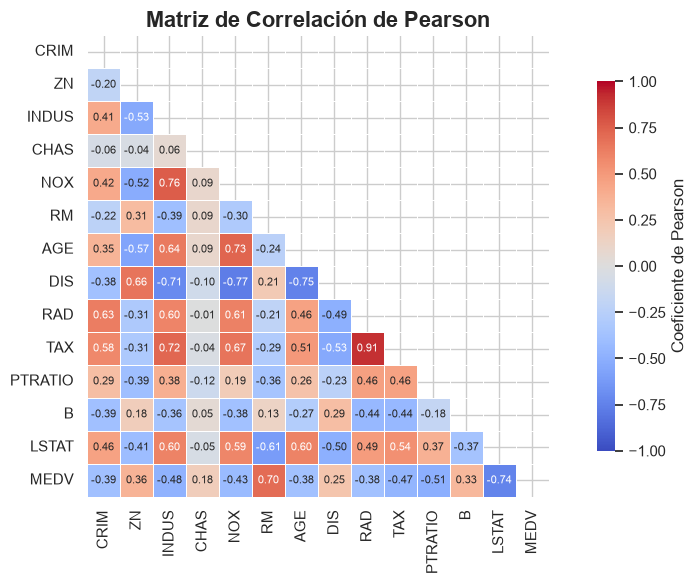

In [19]:
# Se vuelve a pasar la variable CHAS a entero
house_pricing['CHAS'] = house_pricing['CHAS'].astype('int64')

matriz_correlacion = house_pricing.corr(method = 'pearson')

# Se enmascara el triángulo superior para no repetir cada coeficiente dos veces.
mascara = np.triu(np.ones_like(matriz_correlacion, dtype = bool))

fig, ax = plt.subplots(figsize = (10, 6))

sns.heatmap(matriz_correlacion, mask = mascara, annot = True, fmt = '.2f',
            annot_kws = {'size' : 8}, cmap = 'coolwarm', vmin = -1, vmax = 1,
            center = 0, square = True, linewidths = 0.5,
            cbar_kws = {'shrink' : 0.8, 'label' : 'Coeficiente de Pearson'}, ax = ax)

ax.set_title('Matriz de Correlación de Pearson', fontweight = 'bold', fontsize = 16)
plt.tight_layout()
plt.show()

Se observa que `LSTAT` (−0,74) y `RM` (0,70) son las únicas dos que alcanzan 0,70 en valor absoluto, seguidas por `PTRATIO` (−0,51), `INDUS` (−0,48) y `TAX` (−0,47). En el extremo opuesto, `CHAS` (0,18) y `DIS` (0,25) prácticamente no presentan asociación lineal con el precio.

POr otro lado, si se ve que varias predictoras están fuertemente correlacionadas entre sí. El caso extremo es `RAD`–`TAX` (0,91), consistente con la bimodalidad de ambas variables. A ese par se suman `NOX`–`DIS` (−0,77), `INDUS`–`NOX` (0,76), `AGE`–`DIS` (−0,75), `NOX`–`AGE` (0,73), `INDUS`–`TAX` (0,72) e `INDUS`–`DIS` (−0,71).

Este fenómeno se explica por la mera naturaleza de los datos, ya que nos encontramos con un grupo de variables que describen un mismo fenómeno: zonas industriales, antiguas, contaminadas y próximas a los centros de empleo.

#### Contraste con el coeficiente de Spearman

Ahora se procede a comparar el coeficiente de correlación de Pearson entre las variables predictoras y la de respuesta, con el coeficiente de correlación de Spearman. Comparar ambas magnitudes permite estimar cuánta asociación quedará fuera del alcance de un modelo lineal.

In [20]:
# Pearson mide asociación lineal y Spearman monotonía: comparar ambos revela relaciones curvas.
correlacion_pearson = house_pricing.corr(method = 'pearson')['MEDV'].drop('MEDV')
correlacion_spearman = house_pricing.corr(method = 'spearman')['MEDV'].drop('MEDV')

comparacion_correlaciones = pd.DataFrame({
    'pearson' : correlacion_pearson,
    'spearman' : correlacion_spearman
})

# Diferencia entre magnitudes: cuanto mayor es, más asociación queda fuera del alcance de una recta.
comparacion_correlaciones['diferencia'] = (comparacion_correlaciones['spearman'].abs() - comparacion_correlaciones['pearson'].abs())

# Se ordena por la magnitud de Pearson para leer primero las predictoras más fuertes del modelo lineal.
orden_pearson = comparacion_correlaciones['pearson'].abs().sort_values(ascending = False).index
comparacion_correlaciones = comparacion_correlaciones.reindex(orden_pearson)

print(f"\n Correlación con MEDV (Pearson vs. Spearman): \n{comparacion_correlaciones}")


 Correlación con MEDV (Pearson vs. Spearman): 
         pearson  spearman  diferencia
LSTAT     -0.738    -0.853       0.115
RM         0.695     0.634      -0.062
PTRATIO   -0.508    -0.556       0.048
INDUS     -0.484    -0.578       0.095
TAX       -0.469    -0.562       0.094
NOX       -0.427    -0.563       0.135
CRIM      -0.388    -0.559       0.171
RAD       -0.382    -0.347      -0.035
AGE       -0.377    -0.548       0.171
ZN         0.360     0.438       0.078
B          0.333     0.186      -0.148
DIS        0.250     0.446       0.196
CHAS       0.175     0.141      -0.035


El contraste no muestra diferencias marcadas entre ambos coeficientes. Las mayores brechas se dan en DIS (0,250 contra 0,446), AGE (−0,377 contra −0,548), CRIM (−0,388 contra −0,559) y NOX (−0,427 contra −0,563), pero en todos los casos se mantiene el orden de magnitud.

### Codificación de Variables Categóricas

En este dataset las 13 predictoras ya son numéricas, por lo que no hay que codificar variables categóricas.

### División en Conjuntos de Entrenamiento y Prueba

Se reserva el 20%de las observaciones para prueba y se entrena con el 80% restante.

Se procede a realizar la división antes de proceder con el escalado de las variables, para evitar el *data leakage*.

In [21]:
from sklearn.model_selection import train_test_split

# Se separan las 13 predictoras (X) de la variable de respuesta (y).
X = house_pricing.drop(columns = 'MEDV')
y = house_pricing['MEDV']

# El 20% se reserva para prueba y no se usa hasta la evaluación final.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape[0]} filas y {X_train.shape[1]} predictoras")
print(f"Prueba: {X_test.shape[0]} filas y {X_test.shape[1]} predictoras")

Entrenamiento: 404 filas y 13 predictoras
Prueba: 102 filas y 13 predictoras


### Escalado de Variables

Se procede a escalar las variables en el set de entrenamiento utilizando `StandarScaler`.

In [22]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()

X_train_escalado = escalador.fit_transform(X_train)
X_test_escalado = escalador.transform(X_test)

resumen_escalado = pd.DataFrame({
    'media_train' : X_train_escalado.mean(axis = 0),
    'desvio_train' : X_train_escalado.std(axis = 0),
    'media_test' : X_test_escalado.mean(axis = 0),
    'desvio_test' : X_test_escalado.std(axis = 0)
}, index = X_train.columns)

print(f"\n Media y desvío por variable después del escalado: \n{resumen_escalado}")


 Media y desvío por variable después del escalado: 
         media_train  desvio_train  media_test  desvio_test
CRIM          -0.000         1.000      -0.057        0.585
ZN             0.000         1.000      -0.112        0.802
INDUS         -0.000         1.000       0.109        0.985
CHAS          -0.000         1.000       0.205        1.312
NOX           -0.000         1.000       0.085        0.927
RM            -0.000         1.000      -0.189        0.817
AGE            0.000         1.000       0.125        0.986
DIS            0.000         1.000      -0.088        0.921
RAD           -0.000         1.000       0.102        1.036
TAX           -0.000         1.000       0.053        1.025
PTRATIO       -0.000         1.000      -0.048        1.013
B             -0.000         1.000       0.027        1.021
LSTAT          0.000         1.000       0.266        1.156


## Regresión Lineal Múltiple

Se ajusta el primer modelo sobre las 13 predictoras escaladas. Servirá como referencia para comparar los modelos que se incorporen después.

Se calculan tres métricas para el conjunto de entrenamiento y el de prueba:

- **R²**: proporción de la variabilidad de `MEDV` que el modelo logra explicar.
- **RMSE** (raíz del error cuadrático medio): el error típico, expresado en miles de dólares.
- **MAE** (error absoluto medio): el promedio de los errores en valor absoluto, también en miles de dólares.

In [23]:
# Función auxiliar para calcular métricas.
def calcular_metricas(y_real, y_predicho):
    return {
        'R2' : r2_score(y_real, y_predicho),
        'RMSE' : np.sqrt(mean_squared_error(y_real, y_predicho)),
        'MAE' : mean_absolute_error(y_real, y_predicho)
    }

In [24]:
regresion_lineal = LinearRegression()
regresion_lineal.fit(X_train_escalado, y_train)

y_pred_train = regresion_lineal.predict(X_train_escalado)
y_pred_test = regresion_lineal.predict(X_test_escalado)

# Coeficientes del modelo lineal.
coeficientes_lineal = pd.DataFrame({'coeficiente' : regresion_lineal.coef_}, index = X_train.columns)

# Se ordena por magnitud para identificar las variables con mayor peso en la predicción.
orden_coeficientes = coeficientes_lineal['coeficiente'].abs().sort_values(ascending = False).index
coeficientes_lineal = coeficientes_lineal.reindex(orden_coeficientes)

print(f"Intercepto: {regresion_lineal.intercept_:.3f}")
print(f"\n Coeficientes del modelo: \n{coeficientes_lineal}")

# Métricas para la regresión lineal.
metricas_lineal = pd.DataFrame({
    'train' : calcular_metricas(y_train, y_pred_train),
    'test' : calcular_metricas(y_test, y_pred_test)
})

print(f"\n Regresión lineal múltiple: \n{metricas_lineal}")

Intercepto: 22.687

 Coeficientes del modelo: 
         coeficiente
LSTAT         -4.133
DIS           -3.285
RAD            2.598
RM             2.525
NOX           -2.190
PTRATIO       -2.077
TAX           -2.012
ZN             1.221
CRIM          -0.945
B              0.668
CHAS           0.604
INDUS          0.185
AGE            0.060

 Regresión lineal múltiple: 
      train  test
R2    0.753 0.668
RMSE  4.663 4.827
MAE   3.275 3.448


Como las variables fueron escaladas, cada coeficiente indica cuánto varía el precio predicho ante un cambio de un desvío estándar en esa variable, y por lo tanto son comparables entre sí. El intercepto (22,687) corresponde al precio predicho para un barrio con valores promedio en las 13 predictoras.

`LSTAT` es el coeficiente de mayor magnitud (−4,133), en línea con haber sido también la variable más correlacionada con `MEDV`.

Dos coeficientes, en cambio, no coinciden en signo con su correlación simple.`DIS` presentaba una correlación de 0,250 con `MEDV` y aquí recibe un coeficiente de −3,285, y `RAD` pasa de −0,382 a 2,598. Esa inversión es consecuencia directa de la multicolinealidad observada en la matriz de correlación.

Por el lado de las métricas, el modelo explica el **75,3%** de la variabilidad de los precios en entrenamiento y el **66,8%** en prueba. El RMSE es de 4,663 en train y 4,827 en test.

Por su parte, el MAE (3,275 y 3,448) es en ambos casos menor que el RMSE, lo que indica la presencia de algunas predicciones con error grande que elevan el RMSE sin afectar tanto al MAE, algo compatible con las 16 observaciones en las que `MEDV` está censurada en 50,0.

## Regresión Lineal con Descenso por el Gradiente

En lugar de resolver los coeficientes mínimos cuadrados (OLS), el modelo se ajusta de manera iterativa mediante **descenso por el gradiente**.

Se utilizan tres variantes:

* Gradiente Descendiente. 
* Gradiente Descendiente Estocástico.
* Gradiente Descendiente _mini_batch_.

Las tres minimizan la misma función de costo (el Error Cuadrático Medio) y devuelven el vector de pesos $W$, con el término independiente en la primera posición. 

Comparar sus resultados con los de OLS permite verificar empíricamente si la aproximación iterativa alcanza la misma solución que el método analítico.

#### Funciones

In [25]:
def gradient_descent(X_train, y_train, X_val, y_val, lr=0.01, epochs=100):
    """
    Entrena un modelo de regresión lineal mediante Gradient Descent.
    La función ajusta los pesos W de un modelo lineal de la forma:
        y_pred = X @ W

    utilizando el Error Cuadrático Medio (MSE) como función de costo.

    Parámetros
    ----------
    X_train :
      np.ndarray Matriz de características de entrenamiento de dimensiones (n, m), donde n es la cantidad de muestras y m la cantidad de variables.
    y_train :
      np.ndarray Vector de valores objetivo de entrenamiento de dimensiones (n, 1).
    X_val :
      np.ndarray Matriz de características de validación de dimensiones (p, m), donde p es la cantidad de muestras de validación.
    y_val :
      np.ndarray Vector de valores objetivo de validación de dimensiones (p, 1).
    lr :
      float, optional Tasa de aprendizaje utilizada para actualizar los pesos. Por defecto es 0.01.
    epochs :
      int, optional Cantidad de iteraciones del algoritmo de Gradient Descent. Por defecto es 100.

    Retorna
    -------
    np.ndarray Vector de pesos W de dimensiones (m + 1, 1), incluyendo el término independiente (bias).

    Proceso
    -------
    1. Se agrega una columna de unos a X_train y X_val para representar el término independiente (bias).
    2. Se inicializan aleatoriamente los pesos W.
    3. En cada época:
      - Se calcula la predicción sobre el conjunto de entrenamiento.
      - Se calcula el MSE de entrenamiento.
      - Se calcula la predicción sobre el conjunto de validación.
      - Se calcula el MSE de validación.
      - Se calcula el gradiente de la función de costo respecto de W.
      - Se actualizan los pesos utilizando la regla de Gradient Descent: W = W - lr * gradient
      4. Finalmente, se grafica la evolución del MSE de entrenamiento y validación a lo largo de las épocas.
        El gradiente utilizado corresponde a: ∇J(W) = -(2 / n) X.T (y - XW) donde J(W) es el Error Cuadrático Medio.
    """
    n = X_train.shape[0]
    m = X_train.shape[1]

    o = X_val.shape[0]

    # Poner columna de unos a las matrices X
    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_val = np.hstack((np.ones((o, 1)), X_val))


    # Inicializar pesos aleatorios
    W = np.random.randn(m+1).reshape(m+1, 1)

    train_errors = []  # Para almacenar el error de entrenamiento en cada época
    test_errors = []   # Para almacenar el error de prueba en cada época

    for _ in range(epochs):
        # Calcular predicción y error de entrenamiento
        prediction_train = np.matmul(X_train, W)
        error_train = y_train - prediction_train
        #print(error_train)
        train_mse = np.mean(error_train ** 2)
        train_errors.append(train_mse)

        # Calcular predicción y error de prueba
        prediction_test = np.matmul(X_val, W)
        error_test = y_val - prediction_test
        test_mse = np.mean(error_test ** 2)
        test_errors.append(test_mse)

        # Calcular el gradiente y actualizar pesos
        grad_sum = np.sum(error_train * X_train, axis=0)
        grad_mul = -2/n * grad_sum  # 1xm
        gradient = np.transpose(grad_mul).reshape(-1, 1)  # mx1

        W = W - (lr * gradient)

    # Graficar errores de entrenamiento y prueba
    # Definir una figura
    plt.figure(figsize=(12, 6))
    # Plotear errores de entrenamiento
    plt.plot(train_errors, label='Error de entrenamiento')
    # Plotear errores de prueba
    plt.plot(test_errors, label='Error de validación')
    # Poner labels en los ejes
    plt.xlabel('Época')
    plt.ylabel('Error cuadrático medio')
    # Activar la leyenda
    plt.legend()
    # Poner titulo
    plt.title('Error de entrenamiento y validación vs iteraciones (GD)')
    # Terminar y mostrar gráfico
    plt.show()

    return W


def stochastic_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100):
    """
    Entrena un modelo de regresión lineal mediante Stochastic Gradient Descent (SGD).

    La función ajusta los pesos W de un modelo lineal de la forma:

        y_pred = X @ W

    utilizando el Error Cuadrático Medio (MSE) como función de costo.

    A diferencia de Gradient Descent tradicional, que calcula el gradiente
    utilizando todas las muestras antes de actualizar los pesos, SGD actualiza
    los pesos después de procesar cada muestra individual.

    Parámetros
    ----------
    X_train : np.ndarray
        Matriz de características de entrenamiento de dimensiones (n, m),
        donde n es la cantidad de muestras y m la cantidad de variables.

    y_train : np.ndarray
        Vector de valores objetivo de entrenamiento de dimensiones (n, 1).

    X_test : np.ndarray
        Matriz de características de prueba de dimensiones (p, m).

    y_test : np.ndarray
        Vector de valores objetivo de prueba de dimensiones (p, 1).

    lr : float, optional
        Tasa de aprendizaje utilizada para actualizar los pesos.
        Por defecto es 0.01.

    epochs : int, optional
        Cantidad de épocas de entrenamiento. En cada época se recorren
        todas las muestras de entrenamiento. Por defecto es 100.

    Retorna
    -------
    np.ndarray
        Vector de pesos W de dimensiones (m + 1, 1), incluyendo el
        término independiente (bias).

    Proceso
    -------
    1. Se agrega una columna de unos a X_train y X_test para incorporar
      el término independiente (bias).

    2. Se inicializan aleatoriamente los pesos W.

    3. En cada época se permutan aleatoriamente las muestras de entrenamiento
      para evitar que el orden de los datos afecte al proceso de aprendizaje.

    4. Para cada muestra de entrenamiento:
      - Se calcula la predicción.
      - Se calcula el error entre el valor real y la predicción.
      - Se calcula el error cuadrático de esa muestra.
      - Se calcula el gradiente respecto de los pesos.
      - Se actualizan inmediatamente los pesos.

    5. Después de cada actualización se calcula el MSE sobre el conjunto
      de prueba para observar la evolución del modelo.

    El gradiente utilizado para una muestra individual es:

        ∇J(W) = -2 * x_i.T * (y_i - x_i @ W)

    y la actualización de los pesos es:

        W = W - lr * ∇J(W)

    La principal diferencia respecto de Gradient Descent tradicional es que
    el gradiente se calcula y los pesos se actualizan utilizando una sola
    muestra por vez, en lugar de utilizar todo el conjunto de entrenamiento.
    """
    n = X_train.shape[0]
    m = X_train.shape[1]

    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_test = np.hstack((np.ones((X_test.shape[0], 1)), X_test))

    W = np.random.randn(m + 1).reshape(-1, 1)

    train_errors = []
    test_errors = []

    for i in range(epochs):
        # Permutación aleatoria de los datos
        permutation = np.random.permutation(n)
        X_train = X_train[permutation]
        y_train = y_train[permutation]

        for j in range(n):
            # Obtener una muestra aleatoria de un solo dato para hacer SGD
            x_sample = X_train[j]
            y_sample = y_train[j][0]

            prediction = np.matmul(x_sample, W)
            error = y_sample - prediction
            train_mse = error ** 2
            train_errors.append(train_mse)

            prediction_test = np.matmul(X_test, W)
            error_test = y_test - prediction_test
            test_mse = np.mean(error_test ** 2)
            test_errors.append(test_mse)

            gradient = -2 * error * x_sample.T.reshape(-1, 1)

            W = W - (lr * gradient)


    plt.figure(figsize=(12, 6))
    plt.plot(train_errors, label='Error de entrenamiento')
    plt.plot(test_errors, label='Error de prueba')
    plt.xlabel('Iteración')
    plt.ylabel('Error cuadrático medio')
    plt.legend()
    plt.title('Error de entrenamiento y prueba vs iteraciones (SGD)')
    plt.show()

    return W


def mini_batch_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100, batch_size=11):
    """
    Entrena un modelo de regresión lineal mediante Mini-Batch Gradient Descent.

    La función ajusta los pesos W de un modelo lineal de la forma:

        y_pred = X @ W

    utilizando el Error Cuadrático Medio (MSE) como función de costo.

    Mini-Batch Gradient Descent combina las características de Gradient Descent
    tradicional y Stochastic Gradient Descent (SGD): en lugar de calcular el
    gradiente utilizando todo el conjunto de entrenamiento o una única muestra,
    calcula el gradiente utilizando pequeños lotes (mini-batches) de datos.

    Parámetros
    ----------
    X_train : np.ndarray
        Matriz de características de entrenamiento de dimensiones (n, m),
        donde n es la cantidad de muestras y m la cantidad de variables.

    y_train : np.ndarray
        Vector de valores objetivo de entrenamiento de dimensiones (n, 1).

    X_test : np.ndarray
        Matriz de características de prueba de dimensiones (p, m).

    y_test : np.ndarray
        Vector de valores objetivo de prueba de dimensiones (p, 1).

    lr : float, optional
        Tasa de aprendizaje utilizada para actualizar los pesos.
        Por defecto es 0.01.

    epochs : int, optional
        Cantidad de épocas de entrenamiento. En cada época se recorren
        todos los mini-batches del conjunto de entrenamiento.
        Por defecto es 100.

    batch_size : int, optional
        Cantidad de muestras utilizadas para calcular cada actualización
        de los pesos. Por defecto es 11.

    Retorna
    -------
    np.ndarray
        Vector de pesos W de dimensiones (m + 1, 1), incluyendo el
        término independiente (bias).

    Proceso
    -------
    1. Se agrega una columna de unos a X_train y X_test para incorporar
      el término independiente (bias).

    2. Se inicializan aleatoriamente los pesos W.

    3. En cada época se realiza una permutación aleatoria de las muestras
      de entrenamiento para evitar que el orden de los datos influya
      sistemáticamente en el aprendizaje.

    4. El conjunto de entrenamiento se divide en mini-batches de tamaño
      batch_size.

    5. Para cada mini-batch:
      - Se calcula la predicción:

            y_pred = X_batch @ W

      - Se calcula el error:

            error = y_batch - y_pred

      - Se calcula el MSE del mini-batch.
      - Se calcula el gradiente utilizando todas las muestras del
        mini-batch.
      - Se actualizan inmediatamente los pesos.

    6. Después de cada actualización se calcula el MSE sobre el conjunto
      de prueba para evaluar la evolución del modelo.

    El gradiente utilizado es:

        ∇J(W) = -(2 / batch_size) * X_batch.T @ (y_batch - X_batch @ W)

    y la actualización de los pesos es:

        W = W - lr * ∇J(W)

    La principal diferencia respecto de los otros métodos es el tamaño
    del conjunto utilizado para cada actualización:

        Gradient Descent:
            utiliza todas las muestras.

        Stochastic Gradient Descent:
            utiliza una única muestra.

        Mini-Batch Gradient Descent:
            utiliza un pequeño grupo de muestras.

    Por lo tanto, Mini-Batch Gradient Descent busca un equilibrio entre
    la estabilidad del gradiente calculado sobre todo el dataset y la
    velocidad y frecuencia de actualización característica de SGD.
    """
    n = X_train.shape[0]
    m = X_train.shape[1]

    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_test = np.hstack((np.ones((X_test.shape[0], 1)), X_test))

    W = np.random.randn(m + 1).reshape(-1, 1)

    train_errors = []
    test_errors = []

    for i in range(epochs):

        # Permutación aleatoria de los datos
        permutation = np.random.permutation(n)
        X_train = X_train[permutation]
        y_train = y_train[permutation]


        for j in range(0, n, batch_size):
            # Obtener un lote (mini-batch) de datos
            x_batch = X_train[j:j+batch_size, :]
            y_batch = y_train[j:j+batch_size].reshape(-1, 1)

            prediction = np.matmul(x_batch, W)
            error = y_batch - prediction
            train_mse = np.mean(error ** 2)
            train_errors.append(train_mse)

            gradient = -2 * np.matmul(x_batch.T, error) / batch_size

            W = W - (lr * gradient)

            prediction_test = np.matmul(X_test, W)
            error_test = y_test - prediction_test
            test_mse = np.mean(error_test ** 2)
            test_errors.append(test_mse)

    plt.figure(figsize=(12, 6))
    plt.plot(train_errors, label='Error de entrenamiento')
    plt.plot(test_errors, label='Error de prueba')
    plt.xlabel('Iteración')
    plt.ylabel('Error cuadrático medio')
    plt.legend()
    plt.title('Error de entrenamiento y prueba vs iteraciones (Mini-Batch GD)')
    plt.show()

    return W

### Implementación

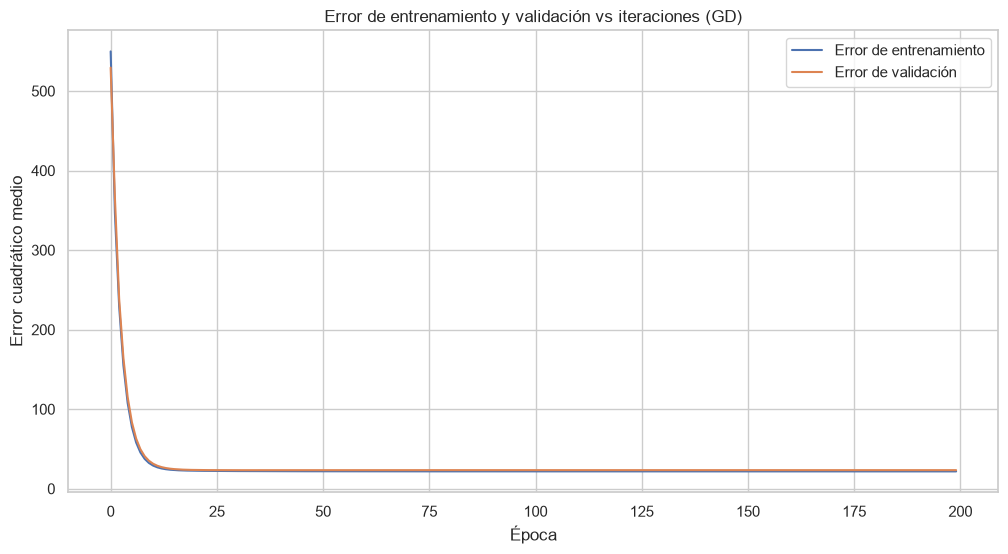

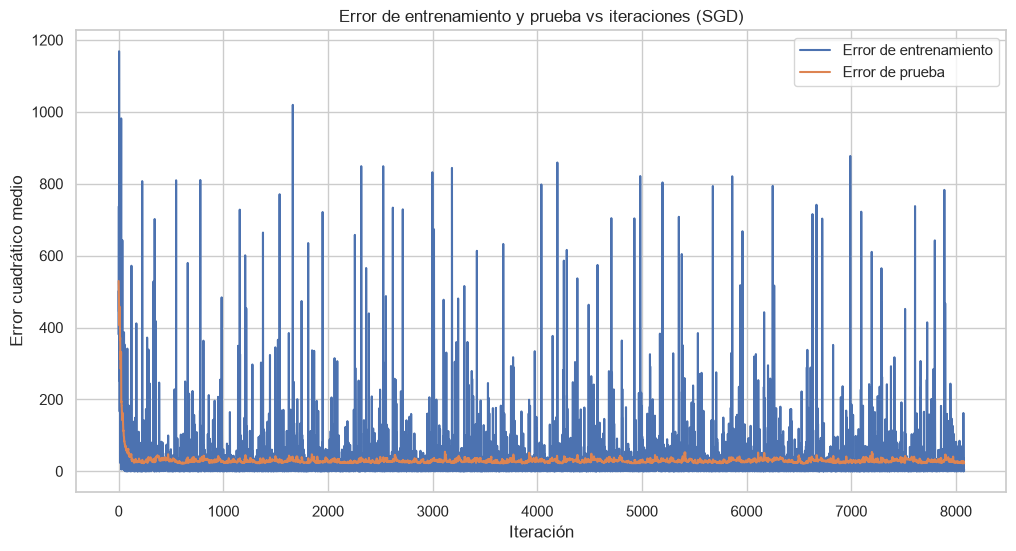

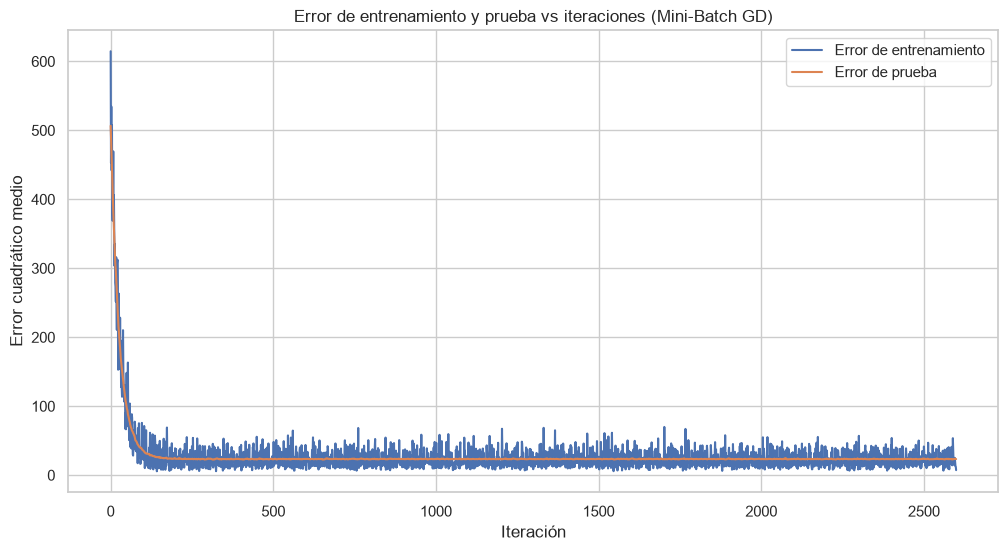

In [26]:
# Vector objetivo como columna.
y_train_columna = y_train.values.reshape(-1, 1)
y_test_columna = y_test.values.reshape(-1, 1)

# Devuelven el vector de pesos W (bias en la posición 0) y no un modelo con .predict().
def predecir_con_pesos(X, W):
    X_con_bias = np.hstack((np.ones((X.shape[0], 1)), X))
    return (X_con_bias @ W).ravel()

np.random.seed(RANDOM_STATE)
W_gd = gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = 0.1, epochs = 200)

np.random.seed(RANDOM_STATE)
W_sgd = stochastic_gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = 0.01, epochs = 20)

np.random.seed(RANDOM_STATE)
W_mbgd = mini_batch_gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = 0.01, epochs = 200, batch_size = 32)

In [27]:
# Las tres variantes, identificadas por su vector de pesos.
pesos_gradiente = {
    'GD por lotes' : W_gd,
    'GD estocástico' : W_sgd,
    'GD mini-batch' : W_mbgd,
}

# Métricas en train y test de cada variante: contrastar ambos conjuntos es lo que revela sobreajuste.
metricas_gd = pd.concat({
    nombre : pd.DataFrame({
        'train' : calcular_metricas(y_train, predecir_con_pesos(X_train_escalado, W)),
        'test' : calcular_metricas(y_test, predecir_con_pesos(X_test_escalado, W))
    })
    for nombre, W in pesos_gradiente.items()
}, axis = 1)

# Comparativa en test: las tres variantes contra la solución analítica de OLS.
comparacion_gradiente = pd.DataFrame({'Regresión Lineal Múltiple (Mínimos Cuadrados)' : metricas_lineal['test']})

for nombre, W in pesos_gradiente.items():
    comparacion_gradiente[nombre] = calcular_metricas(y_test, predecir_con_pesos(X_test_escalado, W))

print(f"\n Descenso del gradiente, train vs. test: \n{metricas_gd}")
print(f"\n Comparativa en el conjunto de prueba: \n{comparacion_gradiente}")

# Si el gradiente converge al mismo mínimo que OLS, coeficientes e intercepto deben coincidir.
# El término independiente ocupa la posición 0 del vector de pesos y el resto son los coeficientes.
comparacion_coeficientes = pd.DataFrame({'OLS' : regresion_lineal.coef_}, index = X_train.columns)
interceptos = {'OLS' : regresion_lineal.intercept_}

for nombre, W in pesos_gradiente.items():
    comparacion_coeficientes[nombre] = W[1:].ravel()
    interceptos[nombre] = W[0][0]

print(f"\n Interceptos: \n{pd.Series(interceptos)}")
print(f"\n Coeficientes: \n{comparacion_coeficientes}")



 Descenso del gradiente, train vs. test: 
     GD por lotes       GD estocástico       GD mini-batch      
            train  test          train  test         train  test
R2          0.753 0.668          0.690 0.679         0.753 0.668
RMSE        4.663 4.829          5.217 4.750         4.663 4.828
MAE         3.273 3.451          3.666 3.364         3.274 3.447

 Comparativa en el conjunto de prueba: 
      Regresión Lineal Múltiple (Mínimos Cuadrados)  GD por lotes  GD estocástico  GD mini-batch
R2                                            0.668         0.668           0.679          0.668
RMSE                                          4.827         4.829           4.750          4.828
MAE                                           3.448         3.451           3.364          3.447

 Interceptos: 
OLS              22.687
GD por lotes     22.687
GD estocástico   22.533
GD mini-batch    22.684
dtype: float64

 Coeficientes: 
           OLS  GD por lotes  GD estocástico  GD mini-batch

### Análisis de Resultados

Se observa que las métricas para evaluar el rendimiento de los modelos para todas las metodologías son prácticamente similares.

Por el lado de los gráficos, el error cae rápido en las primeras épocas y después se aplana, con las curvas de entrenamiento y prueba cerca una de otra y sin volver a subir, lo que descarta sobreajuste. La del estocástico es visiblemente más irregular que las otras dos, coherente con el ruido de sus actualizaciones.

## Métodos de Regularización

A continuación, se prueban métodos de regularización **Ridge**, **Lasso** y **ElasticNet** para combatir la multicolinealidad y observar si existe una mejora en el rendimiento de los modelos.

La selección de la intensidad de regularización ($\alpha$) y del balance (`l1_ratio`) se realiza mediante validación cruzada de 5 pliegues (5-Fold CV) exclusivamente sobre el conjunto de entrenamiento para evitar fuga de información (data leakage).

In [28]:
# Grilla de valores de alpha y pliegues de validación cruzada.
grilla_alphas = np.logspace(-4, 3, 100)
pliegues = KFold(n_splits = 5, shuffle = True, random_state = RANDOM_STATE)

# Función para encontrar el valor óptimo de alpha.
def buscar_mejor_alpha(modelo, rejilla):
    tuberia = Pipeline([('escalador', StandardScaler()), ('modelo', modelo)])
    busqueda = GridSearchCV(tuberia, rejilla, cv = pliegues,
                            scoring = 'neg_root_mean_squared_error', n_jobs = -1)
    busqueda.fit(X_train, y_train)
    return busqueda.best_params_

# Busqueda de alphas.
mejor_ridge = buscar_mejor_alpha(Ridge(), {'modelo__alpha' : grilla_alphas})
mejor_lasso = buscar_mejor_alpha(Lasso(max_iter = 10000), {'modelo__alpha' : grilla_alphas})
mejor_elastic = buscar_mejor_alpha(ElasticNet(max_iter = 10000), {'modelo__alpha' : grilla_alphas, 'modelo__l1_ratio' : [0.1, 0.5, 0.9]})

alpha_ridge = mejor_ridge['modelo__alpha']
alpha_lasso = mejor_lasso['modelo__alpha']
alpha_elastic = mejor_elastic['modelo__alpha']
l1_ratio_elastic = mejor_elastic['modelo__l1_ratio']

print("Alpha Óptimos")
print(f"Ridge: {alpha_ridge:.4f}")
print(f"Lasso: {alpha_lasso:.4f}")
print(f"ElasticNet: {alpha_elastic:.4f} | l1_ratio: {l1_ratio_elastic:.2f}")

# Ajuste de modelos
ridge_cv = Ridge(alpha = alpha_ridge).fit(X_train_escalado, y_train)
lasso_cv = Lasso(alpha = alpha_lasso, max_iter = 10000).fit(X_train_escalado, y_train)
elastic_cv = ElasticNet(alpha = alpha_elastic, l1_ratio = l1_ratio_elastic,
                        max_iter = 10000).fit(X_train_escalado, y_train)

# Comparación de métricas.
comparativa_regularizacion = pd.DataFrame({
    'Regresión Lineal Múltiple (Mínimos Cuadrados)' : metricas_lineal['test']
})

for nombre, W in pesos_gradiente.items():
    comparativa_regularizacion[nombre] = calcular_metricas(y_test, predecir_con_pesos(X_test_escalado, W))

for nombre, modelo in [('Ridge', ridge_cv), ('Lasso', lasso_cv), ('ElasticNet', elastic_cv)]:
    comparativa_regularizacion[nombre] = calcular_metricas(y_test, modelo.predict(X_test_escalado))

print(f"\n Comparativa de rendimiento en test \n{comparativa_regularizacion}")

# Coeficientes de todos los modelos.
df_coeficientes = pd.DataFrame({'OLS' : regresion_lineal.coef_}, index = X_train.columns)

for nombre, W in pesos_gradiente.items():
    df_coeficientes[nombre] = W[1:].ravel()          # el bias ocupa la posición 0

for nombre, modelo in [('Ridge', ridge_cv), ('Lasso', lasso_cv), ('ElasticNet', elastic_cv)]:
    df_coeficientes[nombre] = modelo.coef_

print(f"\n Coeficientes por modelo \n{df_coeficientes}")

# Variables descartadas.
print("\n Variables descartadas (coeficiente exactamente cero) ")

for nombre in df_coeficientes.columns:
    descartadas = df_coeficientes.index[df_coeficientes[nombre] == 0].tolist()
    print(f"  {nombre:20s}: {descartadas if descartadas else 'ninguna'}")

Alpha Óptimos
Ridge: 6.4281
Lasso: 0.0298
ElasticNet: 0.0254 | l1_ratio: 0.50

 Comparativa de rendimiento en test 
      Regresión Lineal Múltiple (Mínimos Cuadrados)  GD por lotes  GD estocástico  GD mini-batch  Ridge  Lasso  ElasticNet
R2                                            0.668         0.668           0.679          0.668  0.672  0.668       0.671
RMSE                                          4.827         4.829           4.750          4.828  4.802  4.827       4.807
MAE                                           3.448         3.451           3.364          3.447  3.416  3.436       3.416

 Coeficientes por modelo 
           OLS  GD por lotes  GD estocástico  GD mini-batch  Ridge  Lasso  ElasticNet
CRIM    -0.945        -0.938           0.551         -0.954 -0.889 -0.860      -0.865
ZN       1.221         1.206           0.851          1.209  1.098  1.085       1.071
INDUS    0.185         0.137          -0.022          0.161  0.008 -0.000      -0.000
CHAS     0.604       

### Análisis de Resultados

Primero se realiza una búsqueda de los _alpha_ óptimos, utilizando validación cruzada de 5 pliegues sobre el conjunto de entrenamiento, con el escalador dentro de un `Pipeline`. Esto último para evitar el _data leakage_, dado que los datos se estandarizaron antes de partir los pliegues, interviniendo en el cálculo de la media y el desvío.

Con respecto a los modelos, las métricas sobre datos no vistos son prácticamente idénticas entre los cuatro modelos, esto es, que la regularización no produce una ganancia apreciable en capacidad de generalización.

Se destaca que Lasso y ElasticNet llevan a cero exacto los coeficientes de `INDUS` y `AGE`, las dos predictoras de menor peso en el modelo de mínimos cuadrados, de modo que descartarlas no altera el desempeño. Ridge, en cambio, contrae todos los coeficientes pero no anula ninguno.

## Selección y Evaluación de Métricas de Rendimiento

A lo largo del informe se utilizaron métricas para la performance de los modelos: **$R^2$ (Coeficiente de Determinación)**, **RMSE (Raíz del Error Cuadrático Medio)** y **MAE (Error Absoluto Medio)**. Además, a continuación se agrega una nueva medida, el **MAPE (Error Porcentual Absoluto Medio)**.

Se prescinde de MSE como métrica principal de reporte, porque queda expresada en unidades al cuadrado (dólares al cuadrado), careciendo de interpretabilidad directa.

La evaluación en ambos subconjuntos es el único mecanismo empírico para descomponer el error y evaluar la capacidad de generalización del modelo:

* **Detección de Sobreajuste (*Overfitting*):**  
   Si el modelo memoriza el ruido de los datos de entrenamiento, obtendrá un desempeño excelente en Train ($R^2$ alto, RMSE bajo), pero caerá drásticamente en Test. La brecha entre ambas evaluaciones cuantifica la varianza del modelo.

* **Detección de Subajuste (*Underfitting*):**  
   Si las métricas son deficientes tanto en Train como en Test, indica que la familia de modelos (en este caso, hipótesis puramente lineales) carece de la flexibilidad o capacidad representativa necesaria para capturar los patrones subyacentes de los datos (sesgo alto).

* **Validación del Error de Generalización:**  
   El rendimiento sobre el conjunto de prueba es la única estimación insesgada de cómo se comportará el modelo en producción ante observaciones completamente nuevas.

Comparativa de Rendimiento


,R2 (Train),R2 (Test),RMSE (Train),RMSE (Test),MAE (Train),MAE (Test),MAPE % (Train),MAPE % (Test)
Modelo,,,,,,,,
Mínimos Cuadrados,0.753,0.668,4.663,4.827,3.275,3.448,15.843,19.312
GD por lotes,0.753,0.668,4.663,4.829,3.273,3.451,15.838,19.326
GD estocástico,0.690,0.679,5.217,4.750,3.666,3.364,19.525,19.595
GD mini-batch,0.753,0.668,4.663,4.828,3.274,3.447,15.833,19.301
Ridge,0.752,0.672,4.669,4.802,3.248,3.416,15.696,19.101
Lasso,0.752,0.668,4.668,4.827,3.258,3.436,15.767,19.232
ElasticNet,0.752,0.671,4.670,4.807,3.247,3.416,15.699,19.102


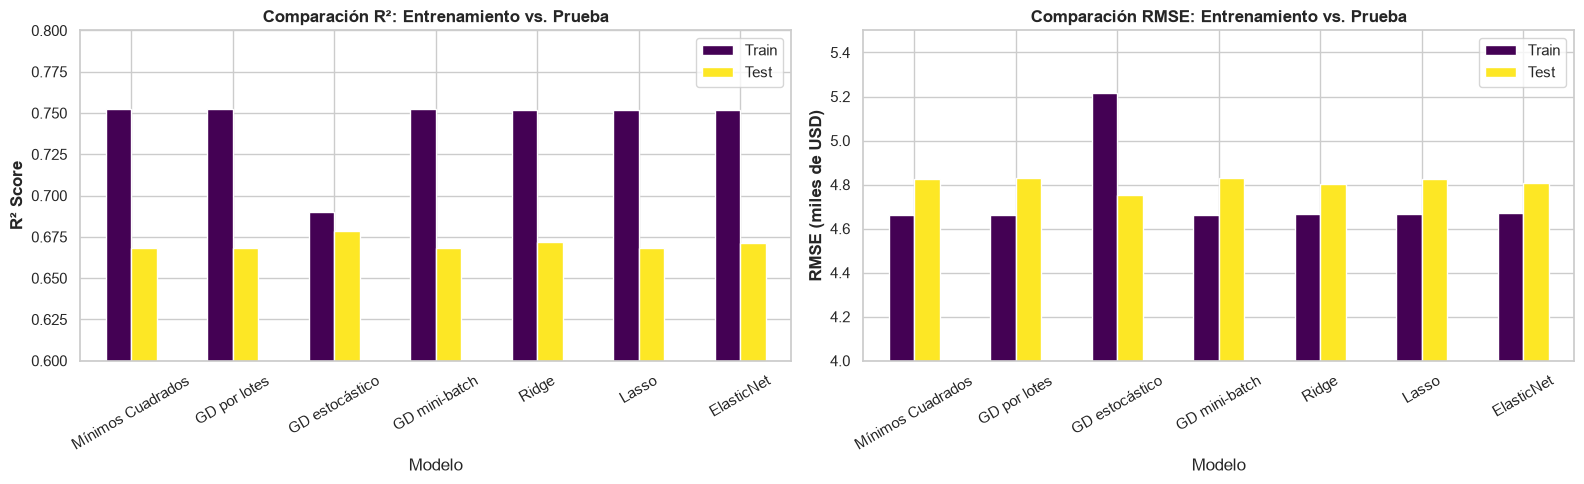

In [29]:
# Función de métricas extendida con R2, RMSE, MAE y MAPE.
def calcular_metricas_completas(y_real, y_predicho):
    return {
        "R2": r2_score(y_real, y_predicho),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_predicho)),
        "MAE": mean_absolute_error(y_real, y_predicho),
        "MAPE (%)": mean_absolute_percentage_error(y_real, y_predicho) * 100,
    }

# Predicciones de cada modelo.
predicciones = {
    "Mínimos Cuadrados": (regresion_lineal.predict(X_train_escalado),
                          regresion_lineal.predict(X_test_escalado)),
}

for nombre, W in pesos_gradiente.items():
    predicciones[nombre] = (predecir_con_pesos(X_train_escalado, W),
                            predecir_con_pesos(X_test_escalado, W))

for nombre, modelo in [("Ridge", ridge_cv), ("Lasso", lasso_cv), ("ElasticNet", elastic_cv)]:
    predicciones[nombre] = (modelo.predict(X_train_escalado), modelo.predict(X_test_escalado))

# Construcción de la tabla comparativa.
filas_metricas = []

for nombre, (y_tr_pred, y_te_pred) in predicciones.items():
    m_train = calcular_metricas_completas(y_train, y_tr_pred)
    m_test = calcular_metricas_completas(y_test, y_te_pred)

    filas_metricas.append(
        {
            "Modelo": nombre,
            "R2 (Train)": m_train["R2"],
            "R2 (Test)": m_test["R2"],
            "RMSE (Train)": m_train["RMSE"],
            "RMSE (Test)": m_test["RMSE"],
            "MAE (Train)": m_train["MAE"],
            "MAE (Test)": m_test["MAE"],
            "MAPE % (Train)": m_train["MAPE (%)"],
            "MAPE % (Test)": m_test["MAPE (%)"],
        }
    )

df_metricas_comparativas = pd.DataFrame(filas_metricas).set_index("Modelo")

print("Comparativa de Rendimiento")
display(df_metricas_comparativas)

# Visualización comparativa de RMSE y R2 entre Train y Test
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))

df_metricas_comparativas[["R2 (Train)", "R2 (Test)"]].plot(
    kind="bar", ax=axes[0], colormap="viridis", ylim=(0.6, 0.8)
)
axes[0].set_title("Comparación R²: Entrenamiento vs. Prueba", fontweight="bold")
axes[0].set_ylabel("R² Score", fontweight="bold")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(["Train", "Test"])

df_metricas_comparativas[["RMSE (Train)", "RMSE (Test)"]].plot(
    kind="bar", ax=axes[1], colormap="viridis", ylim=(4.0, 5.5)
)
axes[1].set_title("Comparación RMSE: Entrenamiento vs. Prueba", fontweight="bold")
axes[1].set_ylabel("RMSE (miles de USD)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(["Train", "Test"])

plt.tight_layout()
plt.show()

### Análisis de Resultados

En los cinco modelos evaluados, el $R^2$ desciende de forma controlada desde 0.753 en entrenamiento hasta un rango de 0.668 a 0.672 en prueba (una caída moderada de entre 8 y 8.5 puntos porcentuales). El RMSE aumenta de 4.66 a alrededor de 4.81 miles de USD. Esta brecha acotada confirma que las hipótesis lineales no memorizan el ruido muestral de entrenamiento.

La diferencia de casi 1.380 USD entre RMSE (4.82) y MAE (3.44) evidencia el impacto de penalizar de forma cuadrática los errores mayores, fenómeno concentrado principalmente en las viviendas con precios atípicos o censurados en el tope de 50.000 USD.

Tanto las tablas numéricas como los gráficos de barras evidencian que mínimos cuadrados, el descenso por el gradiente, Ridge, Lasso y ElasticNet alcanzan prácticamente el mismo nivel de desempeño. Esto reafirma que, con $N = 404$ instancias y $p = 13$ variables, el límite de rendimiento viene impuesto por la linealidad de la hipótesis y no por el método de estimación empleado.

### ¿Se ha conseguido un buen fitting?

El coeficiente $R^2$ pasa de $0.753$ en entrenamiento a un rango de $0.668$ a $0.672$ en prueba (una caída contenida de entre 8 y 8.5 puntos porcentuales). Del mismo modo, el RMSE solo se incrementa de $4.66$ a alrededor de $4.81$ miles de USD. La regularización casi no alteró las métricas de performance. Esto confirma que el modelo generaliza de forma estable y no está memorizando el ruido particular de la muestra de entrenamiento.

Teniendo en cuenta el supuesto de relación lineal entre las variables, y por el análisis que hasta este punto se ha llevado a cabo, se puede decir que se ha alcanzado un buen ajuste.

## Optimización de Hiperparámetros

### Gradiente Descendiente

Se varían los siguientes hiperparámetros:

* **Learning rate ($\alpha$)**: el tamaño del paso en la regla $\beta^{nuevo} = \beta^{viejo} - \alpha \cdot \frac{\partial MSE}{\partial \beta}$.

* **Épocas**: cuántas veces se recorre el conjunto de entrenamiento. Se fijan en 150 para todas las pruebas.

* **Tamaño del lote**: cuántas observaciones intervienen en cada actualización.

Como referencia se toma el MSE de entrenamiento de OLS, que es el mínimo exacto al que el descenso por el gradiente intenta llegar.

In [30]:
def entrenar_con_gradiente(lr, epochs = 150):
    np.random.seed(RANDOM_STATE)
    W = gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = lr, epochs = epochs)
    return W, mean_squared_error(y_train, predecir_con_pesos(X_train_escalado, W))

mse_train_ols = mean_squared_error(y_train, regresion_lineal.predict(X_train_escalado))

print(f"Mínimo alcanzable (MSE de entrenamiento de la regresión lineal): {mse_train_ols:.3f}")

Mínimo alcanzable (MSE de entrenamiento de la regresión lineal): 21.743


#### Variación del learning rate ($\alpha$)

Se mantienen fijas las 150 épocas y se prueban distintos valores de $\alpha$.


 Learning rate = 0.0001


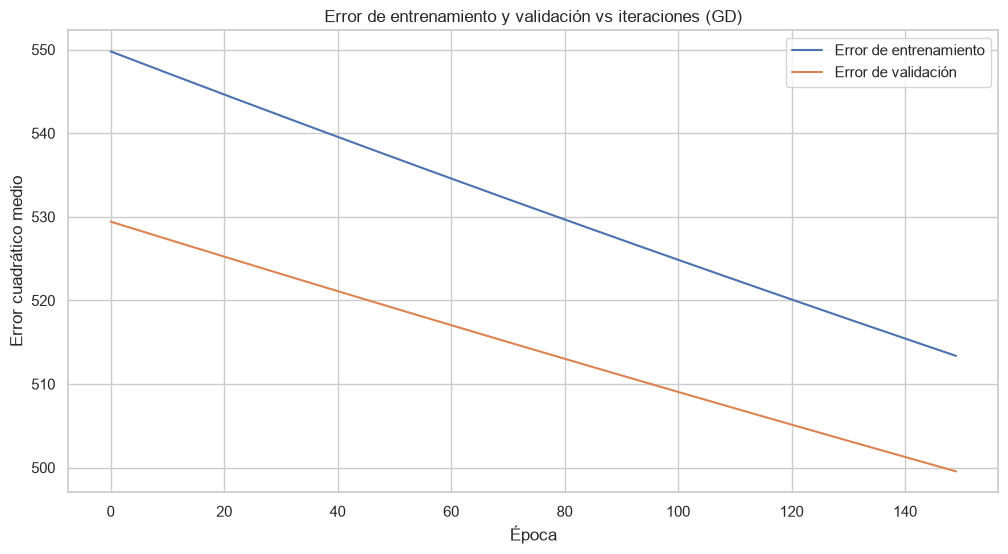


 Learning rate = 0.001


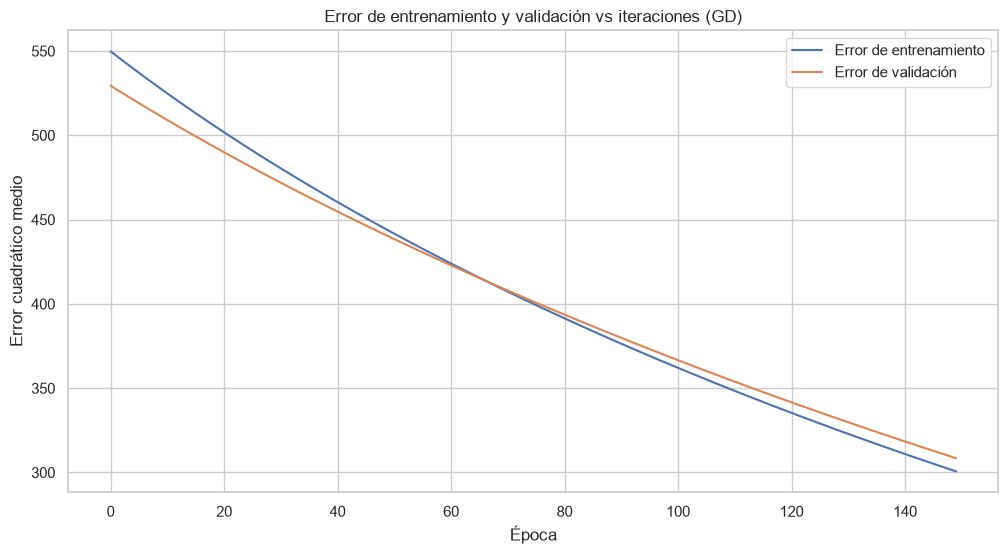


 Learning rate = 0.01


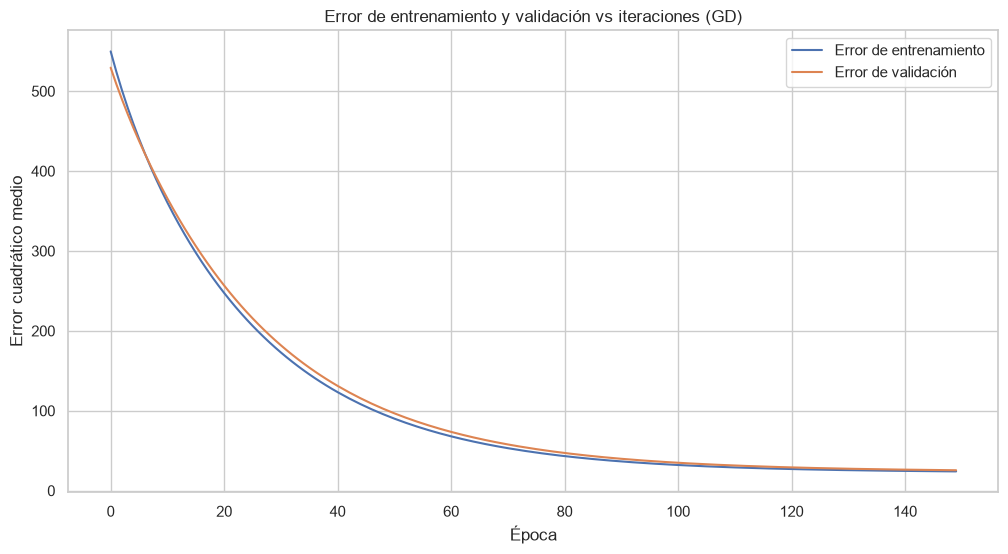


 Learning rate = 0.1


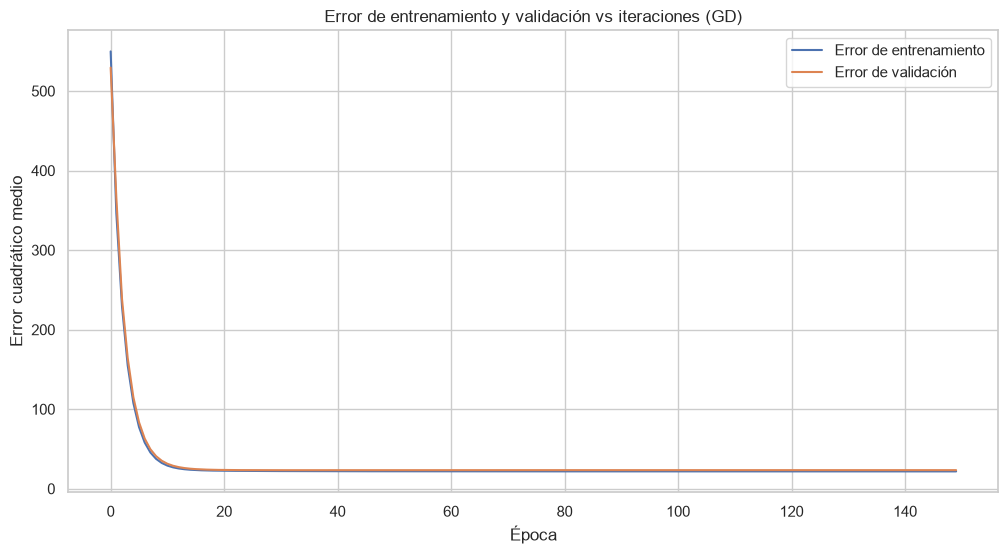


 Learning rate = 0.5


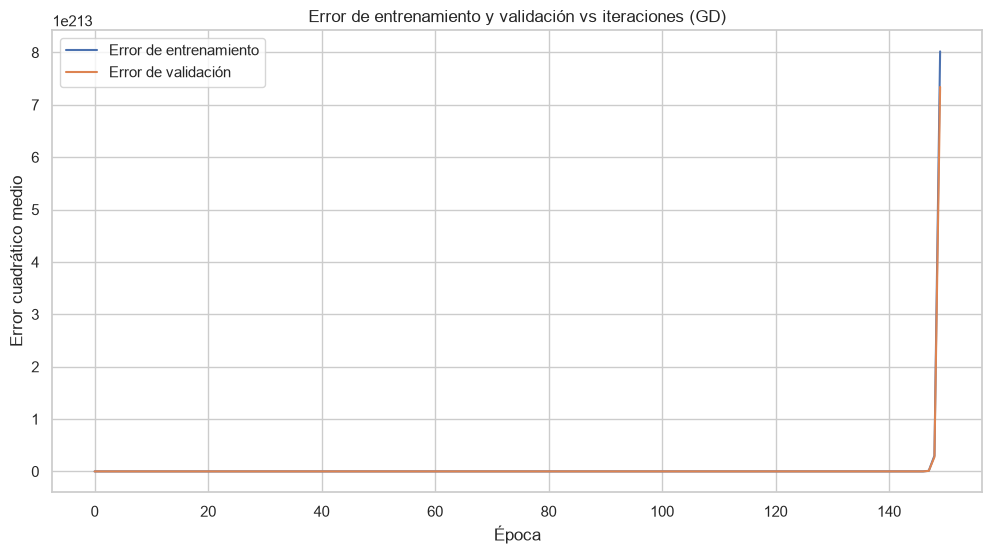


 MSE de entrenamiento alcanzado en 150 épocas: 
              MSE final (train)           resultado
learning rate                                      
0.0001                  513.131  no llega al mínimo
0.001                   299.512  no llega al mínimo
0.01                     24.000            converge
0.1                      21.749            converge
0.5                  2.141e+215             diverge

 Mínimo alcanzable (OLS): 21.743


In [31]:
mse_por_learning_rate = {}

for learning_rate in [0.0001, 0.001, 0.01, 0.1, 0.5]:
    print(f"\n Learning rate = {learning_rate}")
    _, mse_final = entrenar_con_gradiente(lr = learning_rate)
    mse_por_learning_rate[learning_rate] = mse_final

resumen_learning_rate = pd.DataFrame({
    'learning rate' : [f"{lr:g}" for lr in mse_por_learning_rate],
    'MSE final (train)' : [f"{mse:,.3f}" if mse < 1e6 else f"{mse:.3e}"
                           for mse in mse_por_learning_rate.values()],
    'resultado' : ['diverge' if mse > 1e6 else ('converge' if mse < 30 else 'no llega al mínimo')
                   for mse in mse_por_learning_rate.values()]
}).set_index('learning rate')

print(f"\n MSE de entrenamiento alcanzado en 150 épocas: \n{resumen_learning_rate}")
print(f"\n Mínimo alcanzable (OLS): {mse_train_ols:.3f}")

#### Variación del tamaño del lote

El tamaño del lote determina cuántas observaciones intervienen en cada actualización de los pesos y funciona como puente entre las dos variantes extremas: con `batch_size` = 1 el algoritmo equivale al descenso estocástico, y con `batch_size` = 404 (el total de observaciones de entrenamiento) equivale al descenso por lotes.

Se fija $\alpha$ = 0,01 y 150 épocas, y se varía únicamente el tamaño del lote.


 Batch size = 1


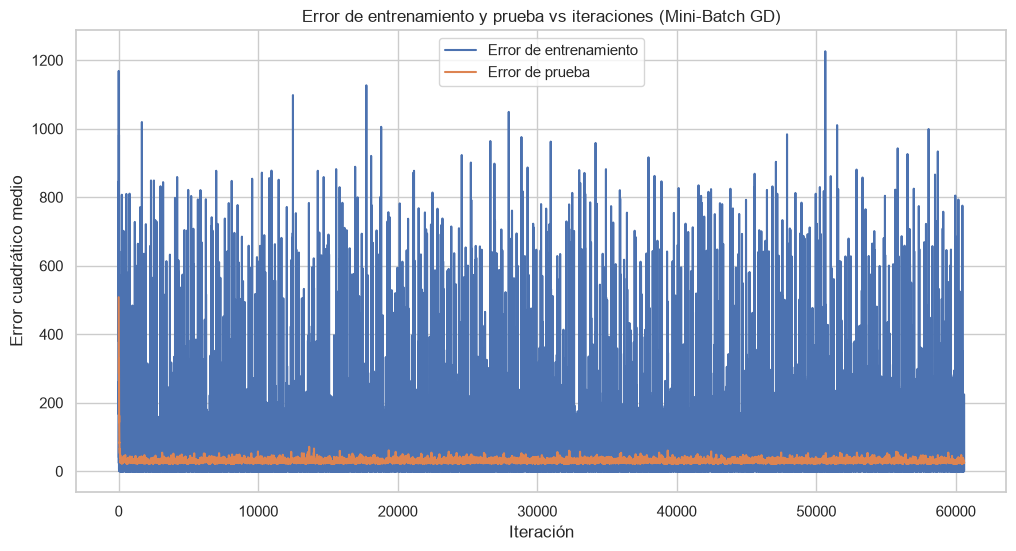


 Batch size = 8


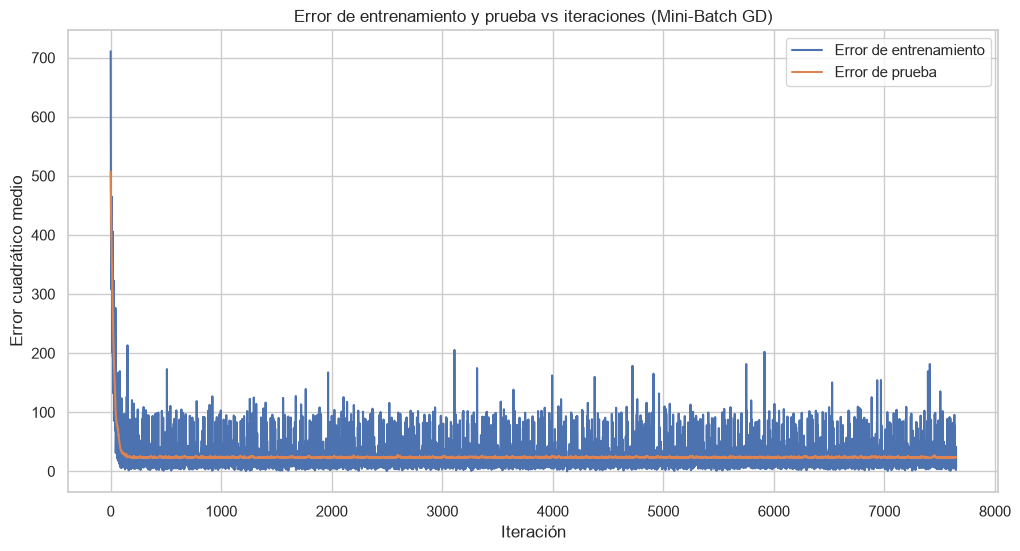


 Batch size = 32


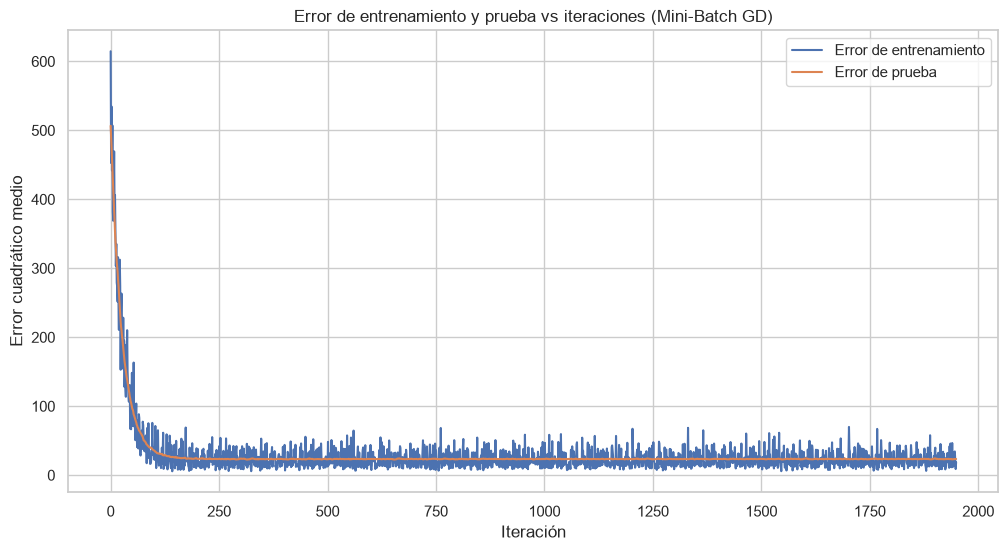


 Batch size = 128


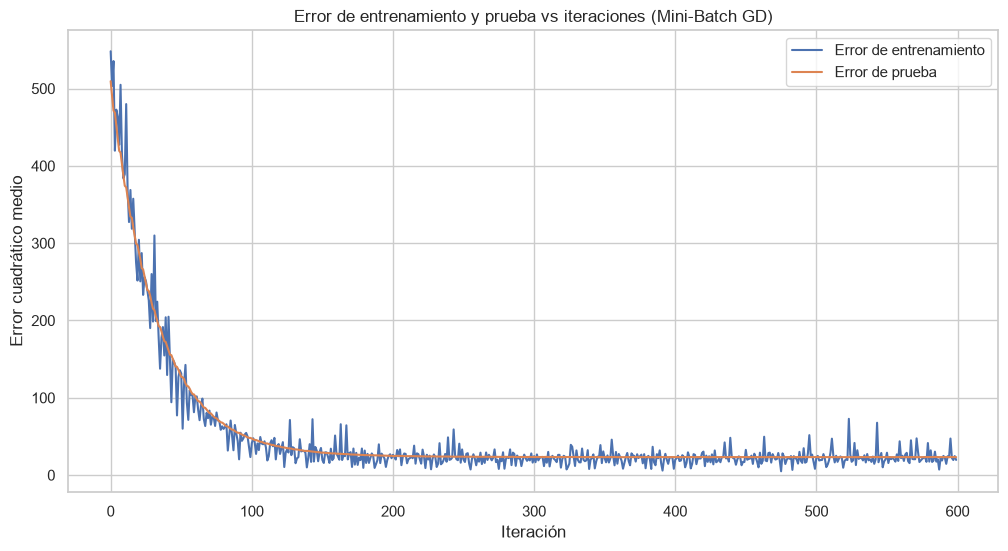


 Batch size = 404


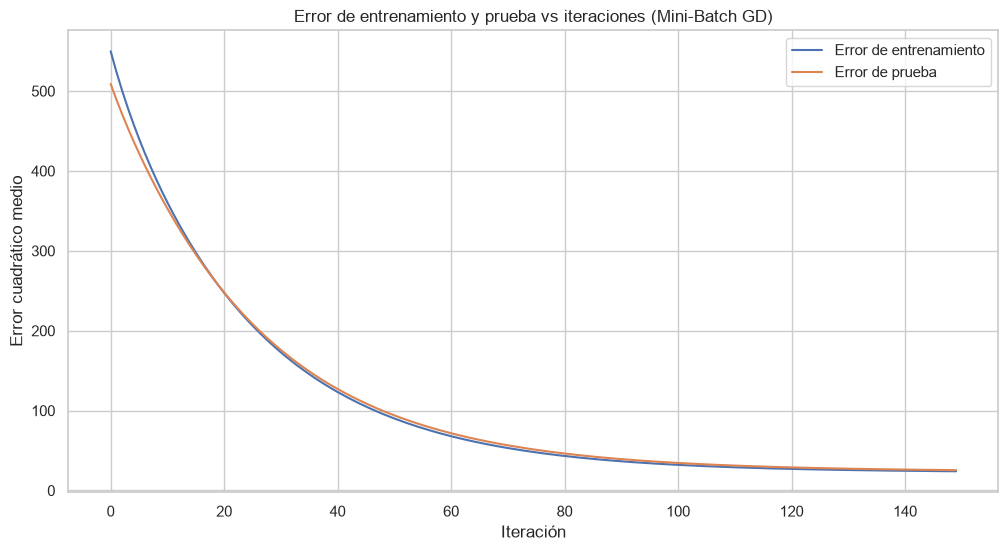


 MSE de entrenamiento alcanzado en 150 épocas: 
            MSE final (train)
batch size                   
1                      23.511
8                      21.837
32                     21.748
128                    21.910
404                    24.000

 Mínimo alcanzable (OLS): 21.743


In [32]:
mse_por_lote = {}

for tamano_lote in [1, 8, 32, 128, 404]:
    print(f"\n Batch size = {tamano_lote}")
    np.random.seed(RANDOM_STATE)
    W_lote = mini_batch_gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = 0.01, epochs = 150, batch_size = tamano_lote)
    mse_por_lote[tamano_lote] = mean_squared_error(y_train, predecir_con_pesos(X_train_escalado, W_lote))

resumen_lote = pd.DataFrame({'MSE final (train)' : mse_por_lote})
resumen_lote.index.name = 'batch size'

print(f"\n MSE de entrenamiento alcanzado en 150 épocas: \n{resumen_lote}")
print(f"\n Mínimo alcanzable (OLS): {mse_train_ols:.3f}")

### Análisis de Resultados

**Sobre el learning rate**, con 150 épocas fijas y un mínimo alcanzable de 21,743:

* **$\alpha$ muy chico (0,0001 y 0,001):** el error desciende, pero con pasos tan pequeños que a las 150 épocas todavía se encuentra muy lejos del mínimo. No es que el algoritmo falle: le falta tiempo.
* **$\alpha$ intermedio (0,01):** queda ya próximo al mínimo.
* **$\alpha$ adecuado (0,1):** alcanza prácticamente el mínimo exacto de OLS.
* **$\alpha$ grande (0,5):** cada paso se pasa de largo y aleja los pesos del mínimo en lugar de acercarlos. El error crece sin control y el entrenamiento **diverge**.

**Sobre el tamaño del lote**, con $\alpha$ = 0,01 fijo, el patrón es distinto: los lotes chicos realizan muchas más actualizaciones por época y por eso avanzan más, aunque cada paso sea menos preciso. Los tamaños intermedios logran el mejor equilibrio, mientras que el lote completo realiza una única actualización por época y queda más atrás con el mismo presupuesto. Con `batch_size` = 1 reaparece el ruido característico del descenso estocástico.

Se concluye que los hiperparámetros del descenso por el gradiente determinan si llega al mínimo y con qué rapidez, pero no "a dónde llega". El MSE de la regresión lineal tiene forma de cuenco y un único mínimo, de modo que toda configuración que converja termina en la misma solución que OLS.

### Ridge y Lasso

Se prueban valores de $\lambda$ entre 0,0001 y 1.000 y, para cada uno, se calcula el error con validación cruzada sobre el conjunto de entrenamiento. Se elige el $\lambda$ con menor error.

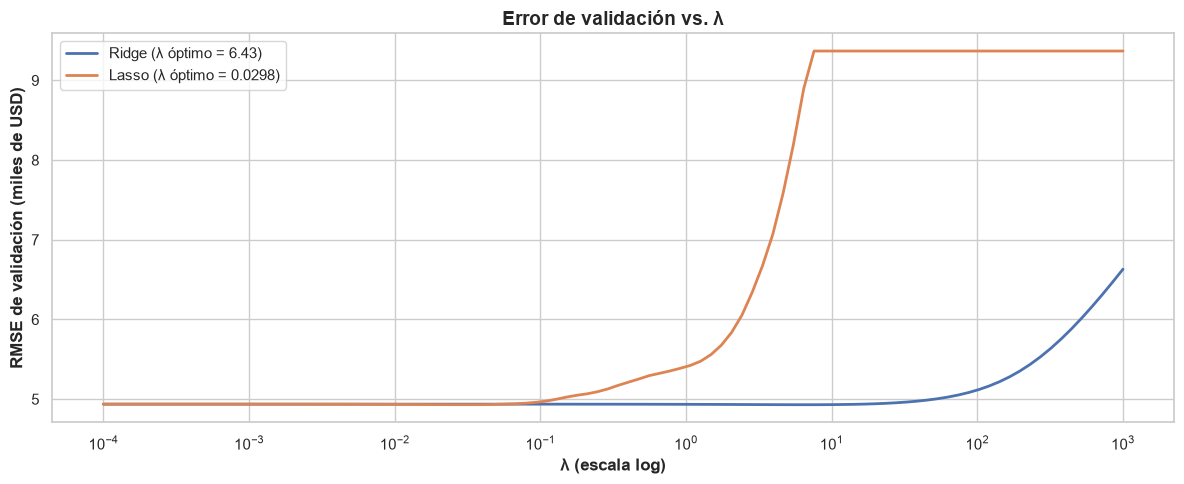

λ óptimo de Ridge: 6.4281 | regularización: 6.4281
λ óptimo de Lasso: 0.0298 | regularización: 0.0298


In [33]:
modelos_penalizados = {'Ridge' : Ridge(),
    'Lasso' : Lasso(max_iter = 10000),
}

# Para cada lambda se calcula el RMSE de validación cruzada, con el escalador dentro del pipeline.
rmse_validacion = {nombre : [] for nombre in modelos_penalizados}

for nombre, modelo in modelos_penalizados.items():
    tuberia = Pipeline([('escalador', StandardScaler()), ('modelo', modelo)])

    for alpha in grilla_alphas:
        tuberia.set_params(modelo__alpha = alpha)
        rmse = -cross_val_score(tuberia, X_train, y_train, cv = pliegues,
                                scoring = 'neg_root_mean_squared_error').mean()
        rmse_validacion[nombre].append(rmse)

# Lambda Óptimo.
alpha_optimo = {
    nombre : grilla_alphas[np.argmin(rmse)] for nombre, rmse in rmse_validacion.items()
}

fig, ax = plt.subplots(figsize = (12, 5))

for nombre, rmse in rmse_validacion.items():
    ax.plot(grilla_alphas, rmse, linewidth = 2,
            label = f"{nombre} (λ óptimo = {alpha_optimo[nombre]:.3g})")

ax.set_xscale('log')
ax.set_title('Error de validación vs. λ', fontweight = 'bold', fontsize = 14)
ax.set_xlabel('λ (escala log)', fontweight = 'bold')
ax.set_ylabel('RMSE de validación (miles de USD)', fontweight = 'bold')
ax.legend(frameon = True)
plt.tight_layout()
plt.show()

# Comprobación: el lambda hallado aquí tiene que ser el mismo que el de la sección de regularización.
print(f"λ óptimo de Ridge: {alpha_optimo['Ridge']:.4f} | regularización: {alpha_ridge:.4f}")
print(f"λ óptimo de Lasso: {alpha_optimo['Lasso']:.4f} | regularización: {alpha_lasso:.4f}")

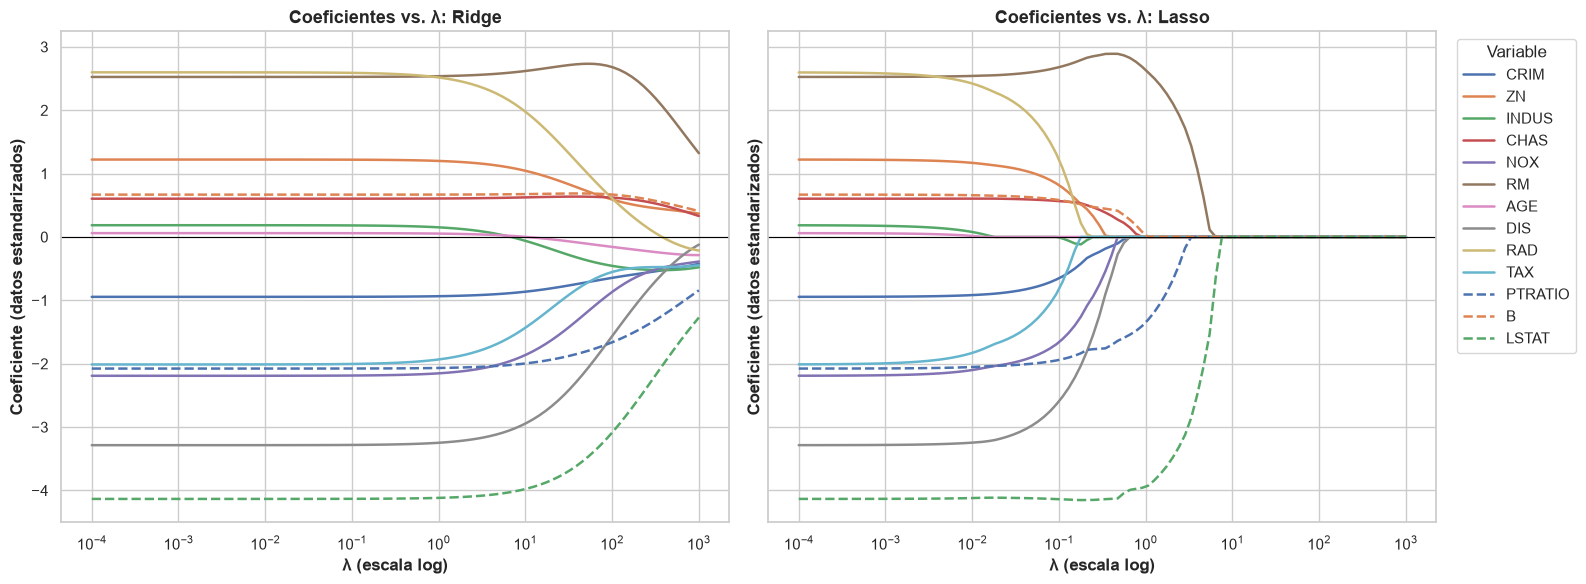

In [34]:
# Coeficientes de cada modelo para cada lambda.
fig, axes = plt.subplots(ncols=2, figsize=(16, 6), sharey=True)

for ax, (nombre, modelo) in zip(axes, modelos_penalizados.items()):
    coeficientes = pd.DataFrame(
        [modelo.set_params(alpha=alpha).fit(X_train_escalado, y_train).coef_ for alpha in grilla_alphas],
        index=grilla_alphas,
        columns=X_train.columns,
    )

    for i, columna in enumerate(coeficientes.columns):
        ax.plot(coeficientes.index, coeficientes[columna], label=columna, linewidth=1.8,
                linestyle="-" if i < 10 else "--")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_title(f"Coeficientes vs. λ: {nombre}", fontweight="bold", fontsize=13)
    ax.set_xlabel("λ (escala log)", fontweight="bold")
    ax.set_ylabel("Coeficiente (datos estandarizados)", fontweight="bold")

axes[1].legend(title="Variable", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [35]:
# Se entrenan Ridge y Lasso con el lambda elegido y se comparan con OLS.
ridge_optimo = Ridge(alpha=alpha_optimo["Ridge"]).fit(X_train_escalado, y_train)
lasso_optimo = Lasso(alpha=alpha_optimo["Lasso"], max_iter=10000).fit(X_train_escalado, y_train)

metricas_optimizados = pd.DataFrame(
    {
        "OLS": calcular_metricas(y_test, regresion_lineal.predict(X_test_escalado)),
        "Ridge": calcular_metricas(y_test, ridge_optimo.predict(X_test_escalado)),
        "Lasso": calcular_metricas(y_test, lasso_optimo.predict(X_test_escalado)),
    }
)

print(f"Métricas en el conjunto de prueba:\n{metricas_optimizados}")
print(f"\nVariables que deja afuera Lasso: {X_train.columns[lasso_optimo.coef_ == 0].tolist()}")

Métricas en el conjunto de prueba:
       OLS  Ridge  Lasso
R2   0.668  0.672  0.668
RMSE 4.827  4.802  4.827
MAE  3.448  3.416  3.436

Variables que deja afuera Lasso: ['INDUS', 'AGE']


### Análisis de Resultados

* **$\lambda$ chico:** el castigo casi no actúa y los dos modelos se comportan igual que la regresión lineal sin regularizar: la curva arranca plana, en el mismo error.
* **$\lambda$ grande:** los coeficientes se achican demasiado, el modelo pierde información y el error sube. En Lasso la subida es brusca porque, a partir de $\lambda$ ≈ 7, todos los coeficientes valen cero y el modelo predice siempre el promedio.
* **Ridge vs. Lasso en los coeficientes:** Ridge los achica a todos de forma pareja, sin anular ninguno. Lasso los va eliminando de a uno, y las últimas variables en desaparecer son `LSTAT` y `RM`, las más correlacionadas con `MEDV`.
* **Resultado en test:** con el $\lambda$ óptimo, Ridge y Lasso obtienen prácticamente las mismas métricas que OLS ($R^2$ ≈ 0,67, RMSE ≈ 4,8). Lasso logra ese mismo resultado dejando afuera `INDUS` y `AGE`.

Por lo tanto, variar $\lambda$ no mejora el modelo porque la regularización sirve para frenar el sobreajuste, y este modelo no lo tiene. Lo mismo pasa con el gradiente descendiente, ningún hiperparámetro mejora el error, porque el límite está en el sesgo del modelo lineal.

## ¿Con qué Modelo nos Quedamos?

**La métrica de decisión: RMSE sobre el conjunto de prueba.**

De las cuatro calculadas, es la más adecuada para elegir, por tres motivos:

* Está en las mismas unidades que el precio (miles de dólares), así que la diferencia entre dos modelos se lee directamente como plata.
* Es la raíz del error cuadrático medio, que es exactamente la función que los modelos minimizan al entrenar. Elegir con la misma medida con la que se ajustó evita premiar a un modelo por algo que nunca intentó optimizar.
* Penaliza más los errores grandes, que en este problema importan: hay viviendas con precio censurado en 50,0 donde el modelo se equivoca por mucho.

En cuanto a los modelos, se descarta el gradiente estocástico. Es el que mejor RMSE obtiene en prueba (4,750), pero su ventaja no proviene de ser mejor modelo sino de haberse detenido en un punto que, por azar, le sienta bien a esta partición particular. Elegirlo sería confundir suerte con calidad.

Descartado el estocástico, el resto de los modelos están prácticamente empatados. El RMSE en prueba va de 4,802 (Ridge) a 4,829 (gradiente por lotes). La diferencia entre el mejor y el peor es de **27 dólares** sobre viviendas que valen decenas de miles, muy por debajo de lo que esta métrica puede distinguir con 102 observaciones de prueba.

Entre modelos de desempeño equivalente se prefiere el más simple, porque es más fácil de interpretar y de sostener ante datos nuevos. Aquí la diferencia la hacen **ElasticNet y Lasso**, al descartar dos variables y alcanzar el mismo resultado con 11 variables en lugar de 13.

Teniendo en cuenta lo anterior, ElasticNet queda a 5 dólares de RMSE del mejor modelo (4,807 contra 4,802 de Ridge), empata con él en MAE (3,416) y en MAPE (19,1%), y lo hace utilizando dos predictoras menos.

Si bien en términos prácticos, la conclusión honesta es que cualquiera de estos modelos serviría, la elección se define por simplicidad y no por capacidad predictiva.

## Conclusión

Se construyó un modelo de regresión lineal múltiple para predecir el precio mediano de viviendas de Boston (`MEDV`) a partir de 13 variables descriptivas del barrio.

El dataset entregado contenía 556 observaciones con valores faltantes. Se descartaron las 29 filas y se trabajó con las 506 observaciones completas resultantes. El análisis exploratorio identificó valores atípicos en 8 variables, que se documentaron pero no se eliminaron, ya que representan barrios reales cuya variabilidad el modelo necesita.

Los datos se dividieron en 404 observaciones de entrenamiento y 102 de prueba, y se estandarizaron ajustando el escalador únicamente con el conjunto de entrenamiento. Sobre esa base se ajustaron cinco modelos: mínimos cuadrados, descenso por el gradiente en sus tres variantes, y las tres formas de regularización (Ridge, Lasso y ElasticNet).

### Resultados

* **Los cinco modelos alcanzan el mismo desempeño.** Esto queda en evidencia al observar las métricas de performance.

* **El descenso por el gradiente converge a la misma solución que mínimos cuadrados** porque el error cuadrático medio de una regresión lineal es una función convexa con un único mínimo global. No hay un segundo mínimo al que un método iterativo pueda caer. Variar los hiperparámetros no modifica dónde llega.

* **La regularización no mejora la predicción** porque no hay sobreajuste que corregir. Con 404 observaciones para estimar 13 coeficientes, los datos determinan los parámetros con holgura: el $R^2$ cae de 0,753 en entrenamiento a 0,668 en prueba, una brecha moderada. Ridge, Lasso y ElasticNet están diseñados para reducir varianza, y en este problema la varianza no es el factor limitante. Sí aporta simplicidad, ya que Lasso y ElasticNet llevan a cero exacto los coeficientes de `INDUS` y `AGE` sin que el desempeño se resienta. Ridge, por su parte, modera los coeficientes que mínimos cuadrados había estimado con magnitudes más extremas, un efecto valioso dada la multicolinealidad detectada (`RAD` y `TAX` correlacionan 0,91).

### ¿Qué limita el resultado?

Un $R^2$ de 0,67 significa que un tercio de la variabilidad del precio queda sin explicar, con un error porcentual típico del 19,3%. Que cinco métodos de estimación distintos topen en el mismo valor indica que el límite no está en cómo se ajustan los parámetros, sino en la forma del modelo.

Hay dos factores que contribuyen a ese techo:

1. **La variable de respuesta está censurada.** `MEDV` tiene un tope de 50,0 y varias observaciones se acumulan exactamente en ese valor. Ninguna recta puede reproducir un truncamiento, de modo que esas viviendas se predicen necesariamente mal.
2. **La relación de algunas predictoras con el precio no es del todo lineal.** Es lo que cabe esperar de un fenómeno económico, y es la causa del sesgo remanente.